# SAMS Vision: fire and smoke hazard detection training

This notebook trains the YOLOv8 detector that SAMS uses to spot fire and smoke in camera frames. The live service (`monitoring/services/hazard_inference.py`) loads `models/vision/hazard/best.pt` and reads which model output is fire and which is smoke from `models/vision/hazard/metadata.json`. It never guesses class names. This notebook writes both files.

## What the model has to do

For every frame, `detect_hazards` runs the detector once at the stored `conf` and `imgsz`, keeps every box whose class name maps to `fire` or `smoke` through the `classes` table, and reports the strongest fire box and the strongest smoke box as `fire_score` and `smoke_score`. `smooth_scores` then averages those scores over the last `score_window` frames. This means:

1. A missed fire costs the most, so the fire threshold is chosen for recall.
2. Every false box on a lamp, a sunset, red clothing, fog, steam, or a cloud raises a frame-level score, so false alarms on images without fire or smoke are measured separately.

| What the live service reads | File | Used for |
|-----------------------------|------|----------|
| the weights | `models/vision/hazard/best.pt` | the detector |
| `classes` | `models/vision/hazard/metadata.json` | maps model output names to `fire` and `smoke` |
| `conf` | `metadata.json` | the confidence cut passed to `predict` |
| `imgsz` | `metadata.json` | the inference image size |
| `model_id` | `metadata.json` | the model name shown in the app |
| `score_window` | `metadata.json` | how many frames `smooth_scores` averages |

## Data source

| Short name | Source | What it shows | Why it is used |
|------------|--------|---------------|----------------|
| dfire | D-Fire (Venancio, Lisboa, Barbosa, 2022), https://github.com/gaiasd/DFireDataset, mirrored on Hugging Face as `hanvithSai/gavin-dfire-raw`, CC BY 4.0 | About 21,500 images with fire only, smoke only, both, or neither. YOLO labels, class 0 is smoke and class 1 is fire | The largest public set with both classes and many fire-like images that contain no fire, which teach the model what not to alarm on |

D-Fire is one published source with a train split and a test split. There is no published val split, so val is carved out of the train split here. Because the data has a single source, there is no leave-one-source-out step.

## Steps

| Section | Step |
|---------|------|
| 0 | Setup, configuration, class list, helper functions |
| 1 | Download D-Fire |
| 2 | Stage the images and check every label file |
| 3 | Preview of the dataset, per split and per image type |
| 4 | Remove duplicates and near-duplicates so no training photo is also a test photo |
| 5 | One table of every image, the fixed val and test splits, and leakage checks |
| 6 | Exploratory data analysis |
| 7 | PCA of images and of object crops |
| 8 | Build the training set; augment the training split only if classes are imbalanced |
| 9 | Training setup: hyperparameters, early stopping, freezing and unfreezing |
| 10 | Experiments E1-E5, one change at a time |
| 11 | Compare the experiments, choose the model, repeat it with other seeds |
| 12 | Evaluate the chosen model in detail on val |
| 13 | Final test, metadata for the live service, export check, model card |
| 14 | Limitations and next steps |

## Rules this notebook follows

1. Validation and test hold only real images. They are never augmented or copied.
2. Class balancing happens only in the training split.
3. Missing training examples are filled with real images first. Augmented copies only fill the gap that is left.
4. Near-duplicate frames stay together: a group of similar frames is either all in train or all in val, and nothing in train looks like a test image.
5. Each experiment changes one thing compared with the best recipe so far, so every gain can be explained.
6. The test split is scored once, after the model has been chosen on validation.
7. Every table is shown as a pandas DataFrame and saved as a CSV file. Every chart is saved as a PNG file.

## 0. Setup

### 0.1 Paths

The notebook runs in Google Colab or locally. In Colab, data is unpacked on the fast local disk (`/content/SAMS`) and models and results are saved to Google Drive so they survive a disconnect. Locally, the project root is used.

In [1]:
from pathlib import Path

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    SAMS_ROOT = Path("/content/SAMS")
else:
    SAMS_ROOT = Path("./SAMS_runtime")

for folder in [
    SAMS_ROOT / "datasets" / "vision" / "hazard",
    SAMS_ROOT / "models" / "vision" / "hazard",
    SAMS_ROOT / "results" / "vision" / "hazard",
]:
    folder.mkdir(parents=True, exist_ok=True)

print("SAMS_ROOT:", SAMS_ROOT.resolve())

Running in Colab: True
SAMS_ROOT: /content/SAMS


In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    here = Path.cwd().resolve()
    if (here / "manage.py").exists():
        DRIVE_ROOT = here
    elif (here.parent / "manage.py").exists():
        DRIVE_ROOT = here.parent
    else:
        DRIVE_ROOT = Path("./SAMS_drive_mirror")

MODELS_DIR = DRIVE_ROOT / "models" / "vision" / "hazard"
RESULTS_DIR = DRIVE_ROOT / "results" / "vision" / "hazard"
DATA_DIR = SAMS_ROOT / "datasets" / "vision" / "hazard"

for folder in [MODELS_DIR, RESULTS_DIR, DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("MODELS_DIR: ", MODELS_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("DATA_DIR:   ", DATA_DIR)

Mounted at /content/drive
MODELS_DIR:  /content/drive/MyDrive/SAMS/models/vision/hazard
RESULTS_DIR: /content/drive/MyDrive/SAMS/results/vision/hazard
DATA_DIR:    /content/SAMS/datasets/vision/hazard


### 0.2 Packages

`albumentations` 2.x is required because the augmentation steps use its newer argument names (`scale_range`, `quality_range`). `onnx` and `onnxruntime` are only used for the export check in section 13.

In [4]:
import subprocess
import sys

PACKAGES = [
    "ultralytics>=8.3.0",
    "albumentations>=2.0.0",
    "huggingface_hub",
    "scikit-learn",
    "seaborn",
    "pandas",
    "matplotlib",
    "pyyaml",
    "Pillow",
    "onnx",
    "onnxruntime",
]

if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])
    print("Packages installed.")
else:
    print("Not in Colab. Install these packages in your environment if an import fails:")
    print(PACKAGES)

Packages installed.


In [5]:
import gc
import hashlib
import json
import random
import shutil
import tarfile
import time
import warnings
from collections import Counter
from datetime import datetime, timezone

import albumentations as A
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import ultralytics
import yaml
from IPython.display import display
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from ultralytics import YOLO

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

version_table = pd.DataFrame([
    {"package": "ultralytics", "version": ultralytics.__version__},
    {"package": "torch", "version": torch.__version__},
    {"package": "albumentations", "version": A.__version__},
    {"package": "scikit-learn", "version": sklearn.__version__},
    {"package": "pandas", "version": pd.__version__},
    {"package": "numpy", "version": np.__version__},
])
display(version_table)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


,package,version
0,ultralytics,8.4.174
1,torch,2.11.0+cu130
2,albumentations,2.0.8
3,scikit-learn,1.6.1
4,pandas,2.2.3
5,numpy,2.1.3


### 0.3 Configuration

Every setting that changes the result is in this one cell, with its meaning in the table below. Change a value here and rerun the notebook. Nothing further down hides its own constants.

In [6]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

HAS_GPU = torch.cuda.is_available()
if HAS_GPU:
    YOLO_DEVICE = 0
    TORCH_DEVICE = "cuda"
else:
    YOLO_DEVICE = "cpu"
    TORCH_DEVICE = "cpu"

# Data checks and splits
NEAR_DUP_BITS = 4
VAL_FRACTION = 0.15
MIN_EVAL_BOXES = 300
EXTRA_BACKGROUND_DIR = DRIVE_ROOT / "datasets" / "vision" / "hazard" / "background"

# EDA crop examples (section 6)
MIN_CROP_PIXELS = 16

# Train-only augmentation when classes are imbalanced
IMBALANCE_RATIO_THRESHOLD = 1.25
MAX_AUG_COPIES_PER_IMAGE = 3

# Training
MAX_EPOCHS = 25
PATIENCE = 3
STAGE_A_EPOCHS = 10
FREEZE_LAYERS = 10
if HAS_GPU:
    BATCH = -1
else:
    BATCH = 4
IMGSZ_BASE = 640
IMGSZ_LARGE = 960
CLOSE_SCORE_GAP = 0.005
REPEAT_SEEDS = [1, 2]

# Evaluation and the live service
SAFETY_CLASS = "fire"
MIN_RECALL_SAFETY = 0.85
THRESHOLD_MIN = 0.05
THRESHOLD_MAX = 0.80
ANALYSIS_CONF = 0.05
MATCH_IOU = 0.50
ROBUST_SAMPLE = 600
BOOTSTRAP_ROUNDS = 1000
CALIBRATION_BINS = 10
FPS_IMAGES = 100
SCORE_WINDOW = 1

config_rows = [
    {"setting": "SEED", "value": SEED, "meaning": "Random seed for sampling, splitting, augmentation, and training"},
    {"setting": "YOLO_DEVICE", "value": YOLO_DEVICE, "meaning": "0 is the first GPU, cpu means no GPU"},
    {"setting": "NEAR_DUP_BITS", "value": NEAR_DUP_BITS, "meaning": "Largest number of differing bits (out of 64) for two image hashes to count as near-duplicates"},
    {"setting": "VAL_FRACTION", "value": VAL_FRACTION, "meaning": "Share of the published train images moved into the fixed val split"},
    {"setting": "MIN_EVAL_BOXES", "value": MIN_EVAL_BOXES, "meaning": "Fewest real boxes each class should have in val and in test"},
    {"setting": "EXTRA_BACKGROUND_DIR", "value": str(EXTRA_BACKGROUND_DIR), "meaning": "Folder for your own SAMS frames with no fire or smoke. Leave it empty if you have none"},
    {"setting": "MIN_CROP_PIXELS", "value": MIN_CROP_PIXELS, "meaning": "Boxes narrower or shorter than this are skipped in the crop example grid"},
    {"setting": "IMBALANCE_RATIO_THRESHOLD", "value": IMBALANCE_RATIO_THRESHOLD, "meaning": "Augment the minority class when majority/minority train box counts exceed this ratio"},
    {"setting": "MAX_AUG_COPIES_PER_IMAGE", "value": MAX_AUG_COPIES_PER_IMAGE, "meaning": "Most augmented copies made from one real training photo"},
    {"setting": "MAX_EPOCHS", "value": MAX_EPOCHS, "meaning": "Upper limit on epochs. Early stopping usually ends sooner"},
    {"setting": "PATIENCE", "value": PATIENCE, "meaning": "Epochs without a val improvement before training stops"},
    {"setting": "STAGE_A_EPOCHS", "value": STAGE_A_EPOCHS, "meaning": "Epochs with the backbone frozen in two-stage fine-tuning"},
    {"setting": "FREEZE_LAYERS", "value": FREEZE_LAYERS, "meaning": "Layers frozen in stage A. 10 is the whole YOLOv8 backbone"},
    {"setting": "BATCH", "value": BATCH, "meaning": "-1 lets Ultralytics pick the largest batch that fits the GPU"},
    {"setting": "IMGSZ_BASE", "value": IMGSZ_BASE, "meaning": "Default training image size"},
    {"setting": "IMGSZ_LARGE", "value": IMGSZ_LARGE, "meaning": "Larger size tested for small, distant flames"},
    {"setting": "CLOSE_SCORE_GAP", "value": CLOSE_SCORE_GAP, "meaning": "Val mAP50-95 gap treated as a tie when choosing the winner"},
    {"setting": "REPEAT_SEEDS", "value": str(REPEAT_SEEDS), "meaning": "Extra seeds used to retrain the chosen recipe"},
    {"setting": "SAFETY_CLASS", "value": SAFETY_CLASS, "meaning": "Class whose threshold is chosen for recall instead of F1"},
    {"setting": "MIN_RECALL_SAFETY", "value": MIN_RECALL_SAFETY, "meaning": "Recall wanted on the safety class when picking its threshold"},
    {"setting": "THRESHOLD_MIN", "value": THRESHOLD_MIN, "meaning": "Lowest confidence threshold allowed for any class"},
    {"setting": "THRESHOLD_MAX", "value": THRESHOLD_MAX, "meaning": "Highest confidence threshold allowed for any class"},
    {"setting": "ANALYSIS_CONF", "value": ANALYSIS_CONF, "meaning": "Confidence used when collecting predictions for the box-by-box analysis"},
    {"setting": "MATCH_IOU", "value": MATCH_IOU, "meaning": "Overlap needed for a prediction to count as finding a label"},
    {"setting": "ROBUST_SAMPLE", "value": ROBUST_SAMPLE, "meaning": "Val images used in the bad-conditions test"},
    {"setting": "BOOTSTRAP_ROUNDS", "value": BOOTSTRAP_ROUNDS, "meaning": "Resampling rounds for the confidence intervals"},
    {"setting": "CALIBRATION_BINS", "value": CALIBRATION_BINS, "meaning": "Confidence bins in the reliability diagram"},
    {"setting": "FPS_IMAGES", "value": FPS_IMAGES, "meaning": "Val images timed in the export check"},
    {"setting": "SCORE_WINDOW", "value": SCORE_WINDOW, "meaning": "Frames the live service averages fire and smoke scores over. 1 means the current frame only"},
]
config_table = pd.DataFrame(config_rows).set_index("setting")
config_table.to_csv(RESULTS_DIR / "config.csv")
display(config_table)

,value,meaning
setting,,
SEED,42,"Random seed for sampling, splitting, augmentat..."
YOLO_DEVICE,0,"0 is the first GPU, cpu means no GPU"
NEAR_DUP_BITS,4,Largest number of differing bits (out of 64) f...
VAL_FRACTION,0.15,Share of the published train images moved into...
MIN_EVAL_BOXES,300,Fewest real boxes each class should have in va...
EXTRA_BACKGROUND_DIR,/content/drive/MyDrive/SAMS/datasets/vision/ha...,Folder for your own SAMS frames with no fire o...
MIN_CROP_PIXELS,16,Boxes narrower or shorter than this are skippe...
IMBALANCE_RATIO_THRESHOLD,1.25,Augment the minority class when majority/minor...
MAX_AUG_COPIES_PER_IMAGE,3,Most augmented copies made from one real train...


### 0.4 Class list

D-Fire ships YOLO labels with class 0 for smoke and class 1 for fire. The ids are kept as published, so the trained model's output names are `smoke` and `fire`.

`HAZARD_CLASSES` is written to `metadata.json` as `classes`. The live service lower-cases each model output name, turns dashes and underscores into spaces, and looks it up in this table. The keys must be exactly `fire` and `smoke`, because the service writes `fire_score` and `smoke_score` from them.

Every image is also given an image type, used throughout the EDA and the frame-level checks: fire only, smoke only, fire and smoke, or background (no labels at all).

In [7]:
CLASS_NAMES = {0: "smoke", 1: "fire"}
NUM_CLASSES = len(CLASS_NAMES)

NAME_TO_ID = {}
for class_id, class_name in CLASS_NAMES.items():
    NAME_TO_ID[class_name] = class_id

CLASS_ORDER = ["fire", "smoke"]
HAZARD_CLASSES = {"fire": ["fire"], "smoke": ["smoke"]}
IMAGE_TYPES = ["fire only", "smoke only", "fire and smoke", "background"]

if SAFETY_CLASS not in NAME_TO_ID:
    raise ValueError(f"SAFETY_CLASS {SAFETY_CLASS} is not one of {list(NAME_TO_ID)}")

DATASET_NAME = "D-Fire"
DATASET_URL = "https://github.com/gaiasd/DFireDataset"
DATASET_HF_REPO = "hanvithSai/gavin-dfire-raw"
DATASET_LICENSE = "CC BY 4.0"


def image_type_of(fire_boxes, smoke_boxes):
    if fire_boxes > 0 and smoke_boxes > 0:
        return "fire and smoke"
    if fire_boxes > 0:
        return "fire only"
    if smoke_boxes > 0:
        return "smoke only"
    return "background"


class_rows = []
for class_id, class_name in CLASS_NAMES.items():
    live_kind = ""
    for kind, names in HAZARD_CLASSES.items():
        if class_name in names:
            live_kind = kind
    if class_name == SAFETY_CLASS:
        threshold_rule = f"highest threshold with recall >= {MIN_RECALL_SAFETY}"
    else:
        threshold_rule = "highest F1"
    class_rows.append({
        "id": class_id,
        "class": class_name,
        "live service kind": live_kind,
        "threshold rule": threshold_rule,
    })
display(pd.DataFrame(class_rows).set_index("id"))

,class,live service kind,threshold rule
id,,,
0,smoke,smoke,highest F1
1,fire,fire,highest threshold with recall >= 0.85


### 0.5 Helper functions

All images are copied into one staging folder, `merged/`, with this layout:

| Folder | Holds |
|--------|-------|
| `images/pool` | Every published training image. The training sets and the val split are chosen from here |
| `images/test` | Every published test image |
| `images/aug` | Augmented training copies, made in section 8 |
| `images/background` | Your own empty SAMS frames from `EXTRA_BACKGROUND_DIR`, if any |
| `images/robust_*` | Degraded val copies for the robustness test in section 12 |
| `labels/...` | One YOLO label file per image, in the matching folder |

Training sets, val, and test are then written as text files that list image paths. Ultralytics accepts these lists, so no image is copied twice. Ultralytics finds each label by swapping `images` for `labels` in the path, which is why the two folder trees mirror each other.

Each label line is `class x_center y_center width height`, with the four box values divided by the image width or height so they lie between 0 and 1.

The duplicate helpers work on a 64-bit difference hash per image. Two hashes are compared by counting the bits that differ (the Hamming distance). 0 means the two images look the same after shrinking, a few bits means a near-duplicate such as the next frame of the same video.

In [8]:
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp"}
MERGED = DATA_DIR / "merged"
LISTS_DIR = MERGED / "lists"

CROP_PADDING = 0.15
REBUILD_DATA = True


def list_images(folder):
    found = []
    folder = Path(folder)
    if not folder.exists():
        return found
    for path in sorted(folder.iterdir()):
        if path.suffix.lower() in IMAGE_SUFFIXES:
            found.append(path)
    return found


def label_path_for(image_path):
    image_path = Path(image_path)
    folder = image_path.parent.name
    return MERGED / "labels" / folder / f"{image_path.stem}.txt"


def read_labels(label_path):
    """Read a YOLO label file into rows of [class_id, xc, yc, w, h]."""
    rows = []
    label_path = Path(label_path)
    if not label_path.is_file():
        return rows
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue
        class_id = int(float(parts[0]))
        xc = float(parts[1])
        yc = float(parts[2])
        w = float(parts[3])
        h = float(parts[4])
        rows.append([class_id, xc, yc, w, h])
    return rows


def clean_box(xc, yc, w, h):
    """Clip a box to the image. Return None if almost nothing is left."""
    x1 = max(0.0, xc - w / 2)
    y1 = max(0.0, yc - h / 2)
    x2 = min(1.0, xc + w / 2)
    y2 = min(1.0, yc + h / 2)
    new_w = x2 - x1
    new_h = y2 - y1
    if new_w < 0.003 or new_h < 0.003:
        return None
    return [(x1 + x2) / 2, (y1 + y2) / 2, new_w, new_h]


def write_labels(label_path, rows):
    """Write rows of [class_id, xc, yc, w, h]. An empty file means a background image."""
    label_path = Path(label_path)
    label_path.parent.mkdir(parents=True, exist_ok=True)
    lines = []
    for row in rows:
        box = clean_box(row[1], row[2], row[3], row[4])
        if box is None:
            continue
        lines.append(f"{int(row[0])} {box[0]:.6f} {box[1]:.6f} {box[2]:.6f} {box[3]:.6f}")
    text = ""
    if lines:
        text = "\n".join(lines) + "\n"
    label_path.write_text(text)
    return len(lines)


def stage_image(source_image, rows, folder, prefix="dfire"):
    """Copy one image into merged/images/<folder> and write its labels."""
    source_image = Path(source_image)
    target_image = MERGED / "images" / folder / f"{prefix}_{source_image.name}"
    target_image.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source_image, target_image)
    write_labels(label_path_for(target_image), rows)
    return target_image


def write_list(name, image_paths):
    """Write a text file with one image path per line, for Ultralytics."""
    LISTS_DIR.mkdir(parents=True, exist_ok=True)
    path = LISTS_DIR / f"{name}.txt"
    lines = []
    for image_path in image_paths:
        lines.append(str(image_path))
    path.write_text("\n".join(lines) + "\n")
    return path


def read_list(list_path):
    paths = []
    for line in Path(list_path).read_text().splitlines():
        if line.strip():
            paths.append(Path(line.strip()))
    return paths


def boxes_per_class(rows):
    """Count boxes by class name in rows of [class_id, xc, yc, w, h]."""
    counts = Counter()
    for row in rows:
        counts[CLASS_NAMES[row[0]]] += 1
    return counts


def class_counts_for_images(image_paths):
    counts = Counter()
    for image_path in image_paths:
        for row in read_labels(label_path_for(image_path)):
            counts[row[0]] += 1
    return counts


def background_count(image_paths):
    empty = 0
    for image_path in image_paths:
        if not read_labels(label_path_for(image_path)):
            empty += 1
    return empty


def counts_table(named_counters, classes=None):
    """One row per class, one column per Counter of class ids."""
    if classes is None:
        classes = CLASS_ORDER
    table = pd.DataFrame(index=classes)
    for column, counter in named_counters.items():
        values = []
        for class_name in classes:
            values.append(int(counter.get(NAME_TO_ID[class_name], 0)))
        table[column] = values
    table.index.name = "class"
    return table


def size_bucket(w, h, width, height, train_size=IMGSZ_BASE):
    """Small, medium, or large, measured after the image is resized for training."""
    scale = train_size / max(width, height)
    area = (w * width * scale) * (h * height * scale)
    if area < 32 * 32:
        return "small"
    if area < 96 * 96:
        return "medium"
    return "large"


CLASS_COLORS = {
    NAME_TO_ID["fire"]: "#e53e3e",
    NAME_TO_ID["smoke"]: "#4a5568",
}


def draw_boxes(ax, image_path, rows, title="", color=None):
    """Draw [class_id, xc, yc, w, h] rows on an image."""
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    ax.imshow(image)
    for row in rows:
        class_id = row[0]
        left = (row[1] - row[3] / 2) * width
        top = (row[2] - row[4] / 2) * height
        box_color = color
        if box_color is None:
            box_color = CLASS_COLORS[class_id]
        rectangle = patches.Rectangle(
            (left, top), row[3] * width, row[4] * height,
            fill=False, linewidth=2, edgecolor=box_color,
        )
        ax.add_patch(rectangle)
        ax.text(left, top, CLASS_NAMES[class_id], color="white", fontsize=7, backgroundcolor=box_color)
    ax.set_title(title, fontsize=9)
    ax.axis("off")


def crop_box(image, xc, yc, w, h, padding=CROP_PADDING):
    """Crop one normalised box out of an open PIL image, with a margin."""
    width, height = image.size
    half_w = w * width * (1 + padding) / 2
    half_h = h * height * (1 + padding) / 2
    center_x = xc * width
    center_y = yc * height
    left = max(0, int(center_x - half_w))
    top = max(0, int(center_y - half_h))
    right = min(width, int(center_x + half_w))
    bottom = min(height, int(center_y + half_h))
    return image.crop((left, top, right, bottom))


def save_figure(fig, name):
    path = RESULTS_DIR / f"{name}.png"
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.show()
    print("Saved figure:", path)


def save_table(frame, name):
    frame.to_csv(RESULTS_DIR / f"{name}.csv")
    display(frame)


def preview_images(image_paths, title, name, columns=4, grid_rows=2):
    """Show a seeded random grid of images with their labels drawn."""
    picks = []
    for image_path in image_paths:
        picks.append(Path(image_path))
    random.Random(SEED).shuffle(picks)
    picks = picks[:columns * grid_rows]
    fig, axes = plt.subplots(grid_rows, columns, figsize=(4.5 * columns, 4.2 * grid_rows))
    for ax in axes.flatten():
        ax.axis("off")
    for ax, image_path in zip(axes.flatten(), picks):
        label_rows = read_labels(label_path_for(image_path))
        draw_boxes(ax, image_path, label_rows, title=f"{image_path.name[:30]}  ({len(label_rows)} boxes)")
    fig.suptitle(title)
    plt.tight_layout()
    save_figure(fig, name)


def free_memory():
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()


def name_prefix(file_name):
    """Letters before the first digit of a file name, which hint at the collection batch."""
    letters = []
    for character in Path(file_name).stem:
        if character.isdigit():
            break
        letters.append(character)
    prefix = "".join(letters).strip("_- ")
    if not prefix:
        return "(none)"
    return prefix


def difference_hash(image_path):
    """64-bit difference hash as 16 hex characters."""
    with Image.open(image_path) as image:
        small = image.convert("L").resize((9, 8))
    pixels = np.asarray(small, dtype=np.int16)
    brighter = pixels[:, 1:] > pixels[:, :-1]
    return np.packbits(brighter.flatten()).tobytes().hex()


def hash_bits(hex_hash):
    return np.frombuffer(bytes.fromhex(hex_hash), dtype=np.uint8)


def stack_hash_bits(hashes):
    arrays = []
    for value in hashes:
        arrays.append(hash_bits(value))
    if not arrays:
        return np.zeros((0, 8), dtype=np.uint8)
    return np.stack(arrays)


POPCOUNT = np.zeros(256, dtype=np.uint8)
for byte_value in range(256):
    POPCOUNT[byte_value] = bin(byte_value).count("1")


def near_duplicate_pairs(query_bits, reference_bits, max_bits, same_set=False, chunk=256):
    """All (query index, reference index, distance) pairs whose hashes differ in at most max_bits bits.

    With same_set=True the two arrays are the same images, and each pair is returned once.
    """
    pairs = []
    if len(query_bits) == 0 or len(reference_bits) == 0:
        return pairs
    for start in range(0, len(query_bits), chunk):
        block = query_bits[start:start + chunk]
        xor = np.bitwise_xor(block[:, None, :], reference_bits[None, :, :])
        distance = POPCOUNT[xor].sum(axis=2)
        query_index, reference_index = np.nonzero(distance <= max_bits)
        for query_number, reference_number in zip(query_index, reference_index):
            query_global = start + int(query_number)
            reference_global = int(reference_number)
            if same_set and reference_global <= query_global:
                continue
            pairs.append((query_global, reference_global, int(distance[query_number, reference_number])))
    return pairs


def find_root(parent, index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index


def join_groups(parent, first, second):
    root_first = find_root(parent, first)
    root_second = find_root(parent, second)
    if root_first != root_second:
        parent[max(root_first, root_second)] = min(root_first, root_second)


if REBUILD_DATA and MERGED.exists():
    shutil.rmtree(MERGED)
    print("Fresh staging folder:", MERGED)
else:
    print("Keeping existing staging folder:", MERGED)
MERGED.mkdir(parents=True, exist_ok=True)

Keeping existing staging folder: /content/SAMS/datasets/vision/hazard/merged


## 1. Download D-Fire

The Hugging Face mirror `hanvithSai/gavin-dfire-raw` stores the original D-Fire release as two archives, `train.tar` and `test.tar`. Each one unpacks into a folder with `images/` and `labels/`. An archive is only unpacked once. A marker file records that it is done.

In [9]:
from huggingface_hub import snapshot_download

RAW_DIR = DATA_DIR / "dfire_raw"
snapshot_download(
    repo_id=DATASET_HF_REPO,
    repo_type="dataset",
    local_dir=str(RAW_DIR),
    allow_patterns=["*.tar", "README.md", "MANIFEST.md"],
)

EXTRACTED = DATA_DIR / "dfire"
EXTRACTED.mkdir(parents=True, exist_ok=True)

download_rows = []
for archive_name in ["train.tar", "test.tar"]:
    archive_path = RAW_DIR / archive_name
    if not archive_path.is_file():
        raise FileNotFoundError(archive_path)
    marker = EXTRACTED / f".extracted_{archive_name}"
    if marker.exists():
        status = "already extracted"
    else:
        with tarfile.open(archive_path) as archive:
            archive.extractall(EXTRACTED, filter="data")
        marker.write_text(archive_name)
        status = "extracted now"
    download_rows.append({
        "archive": archive_name,
        "size MB": round(archive_path.stat().st_size / 1e6, 1),
        "status": status,
    })
save_table(pd.DataFrame(download_rows).set_index("archive"), "download_archives")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

,size MB,status
archive,,
train.tar,2598.5,extracted now
test.tar,639.8,extracted now


The table below shows what was found inside the archives: how many images and label files each published split has. D-Fire should have about 17,200 training and 4,300 test images, with one label file per image.

In [10]:
def find_split_dir(split_name):
    """Find the folder named split_name that holds images/ and labels/ inside the extracted archives."""
    for path in sorted(EXTRACTED.rglob(split_name)):
        if path.is_dir() and (path / "images").is_dir() and (path / "labels").is_dir():
            return path
    raise FileNotFoundError(f"No {split_name}/images and {split_name}/labels under {EXTRACTED}")


SPLIT_DIRS = {"train": find_split_dir("train"), "test": find_split_dir("test")}

found_rows = []
for published_split, split_root in SPLIT_DIRS.items():
    label_files = list((split_root / "labels").glob("*.txt"))
    found_rows.append({
        "published split": published_split,
        "folder": str(split_root),
        "images": len(list_images(split_root / "images")),
        "label files": len(label_files),
    })
save_table(pd.DataFrame(found_rows).set_index("published split"), "download_contents")

,folder,images,label files
published split,,,
train,/content/SAMS/datasets/vision/hazard/dfire/train,34442,34442
test,/content/SAMS/datasets/vision/hazard/dfire/test,8612,8612


## 2. Stage the images and check every label file

Every published image is copied into `merged/` with a cleaned label file. Each label file is checked line by line before it is trusted:

| Check | What happens |
|-------|--------------|
| image has no label file | skipped, because an unlabelled image may contain fire |
| image cannot be opened | skipped |
| line does not have five numbers | the line is dropped and counted |
| class id is not 0 or 1 | the line is dropped and counted, and the ids are listed |
| box reaches outside the image | clipped to the image and counted |
| box is almost nothing after clipping | dropped and counted |
| the same box appears twice | the repeat is dropped and counted |
| label file has lines but none survive | the image is skipped, because it is not really a background image |
| label file is empty | kept as a background image: no fire and no smoke |

The published train split goes to `pool` and the published test split goes to `test`.

In [11]:
UNKNOWN_CLASS_IDS = Counter()


def parse_label_file(label_file):
    """Read one published label file, fix what can be fixed, and count every problem.

    Returns the kept rows, a Counter of issues, and False if the file had lines but none were usable.
    """
    issues = Counter()
    rows = []
    seen = set()
    had_lines = False
    for line in Path(label_file).read_text().splitlines():
        parts = line.split()
        if not parts:
            continue
        had_lines = True
        if len(parts) != 5:
            issues["bad lines"] += 1
            continue
        try:
            values = []
            for part in parts:
                values.append(float(part))
        except ValueError:
            issues["bad lines"] += 1
            continue
        class_id = int(values[0])
        if class_id not in CLASS_NAMES:
            issues["unknown class id"] += 1
            UNKNOWN_CLASS_IDS[class_id] += 1
            continue
        box = clean_box(values[1], values[2], values[3], values[4])
        if box is None:
            issues["tiny boxes dropped"] += 1
            continue
        shift = abs(box[0] - values[1]) + abs(box[1] - values[2]) + abs(box[2] - values[3]) + abs(box[3] - values[4])
        if shift > 1e-6:
            issues["boxes clipped to the image"] += 1
        key = (class_id, round(box[0], 4), round(box[1], 4), round(box[2], 4), round(box[3], 4))
        if key in seen:
            issues["repeated boxes removed"] += 1
            continue
        seen.add(key)
        rows.append([class_id, box[0], box[1], box[2], box[3]])
    usable = True
    if had_lines and not rows:
        usable = False
    return rows, issues, usable


CHECK_COLUMNS = [
    "staged",
    "background images",
    "boxes kept",
    "skipped, no label file",
    "skipped, unreadable image",
    "skipped, no usable box in a non-empty file",
    "bad lines",
    "unknown class id",
    "tiny boxes dropped",
    "boxes clipped to the image",
    "repeated boxes removed",
]
DFIRE_SPLITS = {"train": "pool", "test": "test"}

STAGED = []
check_rows = []
staged_class_counts = Counter()
for published_split, folder in DFIRE_SPLITS.items():
    split_root = SPLIT_DIRS[published_split]
    images = list_images(split_root / "images")
    counts = Counter()
    for image_path in images:
        label_file = split_root / "labels" / f"{image_path.stem}.txt"
        if not label_file.is_file():
            counts["skipped, no label file"] += 1
            continue
        try:
            with Image.open(image_path) as image:
                image.verify()
        except Exception:
            counts["skipped, unreadable image"] += 1
            continue
        rows, issues, usable = parse_label_file(label_file)
        counts.update(issues)
        if not usable:
            counts["skipped, no usable box in a non-empty file"] += 1
            continue
        if not rows:
            counts["background images"] += 1
        counts["boxes kept"] += len(rows)
        staged_class_counts.update(boxes_per_class(rows))
        target = stage_image(image_path, rows, folder)
        STAGED.append({
            "folder": folder,
            "published_split": published_split,
            "original_name": image_path.name,
            "image": target,
        })
        counts["staged"] += 1
    row = {"published split": published_split, "staged as": folder, "images found": len(images)}
    for column in CHECK_COLUMNS:
        row[column] = int(counts[column])
    check_rows.append(row)

save_table(pd.DataFrame(check_rows).set_index("published split"), "label_checks")

requirements: Ultralytics requirement ['pi-heif'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 192ms
Prepared 1 package in 20ms
Installed 1 package in 2ms
 + pi-heif==1.4.0

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



,staged as,images found,staged,background images,boxes kept,"skipped, no label file","skipped, unreadable image","skipped, no usable box in a non-empty file",bad lines,unknown class id,tiny boxes dropped,boxes clipped to the image,repeated boxes removed
published split,,,,,,,,,,,,,
train,pool,34442,17221,7833,21349,0,17221,0,0,0,15,317,0
test,test,8612,4306,2005,5189,0,4306,0,0,0,4,62,0


Unknown class ids and the class totals. If a class id other than 0 or 1 shows up in large numbers, the published class map has changed and the notebook should not continue. If either class has no boxes at all, the notebook stops here instead of training a model the live service cannot use.

In [12]:
unknown_rows = []
for class_id, count in sorted(UNKNOWN_CLASS_IDS.items()):
    unknown_rows.append({"class id": class_id, "lines dropped": count})
if unknown_rows:
    save_table(pd.DataFrame(unknown_rows).set_index("class id"), "label_unknown_class_ids")
else:
    display(pd.DataFrame([{"result": "Every label line uses class 0 or class 1"}]))

total_rows = []
for class_name in CLASS_ORDER:
    total_rows.append({"class": class_name, "class id": NAME_TO_ID[class_name], "boxes staged": int(staged_class_counts[class_name])})
save_table(pd.DataFrame(total_rows).set_index("class"), "label_class_totals")

for class_name in CLASS_ORDER:
    if staged_class_counts[class_name] == 0:
        raise RuntimeError(f"No {class_name} boxes were staged. Check the D-Fire class ids.")

,result
0,Every label line uses class 0 or class 1


,class id,boxes staged
class,,
fire,1,14684
smoke,0,11854


## 3. Preview of the dataset

### 3.1 Per published split

Eight random images from each published split with their labels. Red boxes are labelled `fire` and grey boxes are labelled `smoke`. Check that red boxes sit on flames and grey boxes on smoke. If they are the other way round, the class ids are swapped and `CLASS_NAMES` must be fixed before going further.

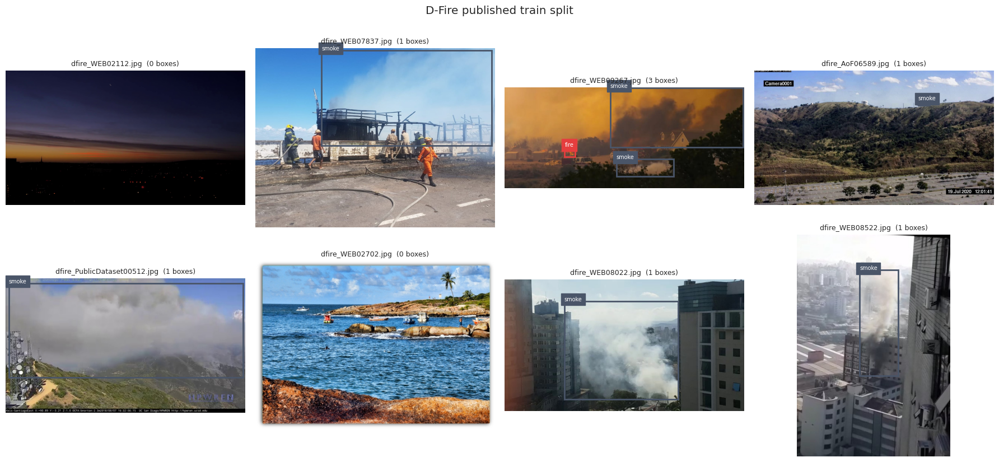

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/preview_published_train.png


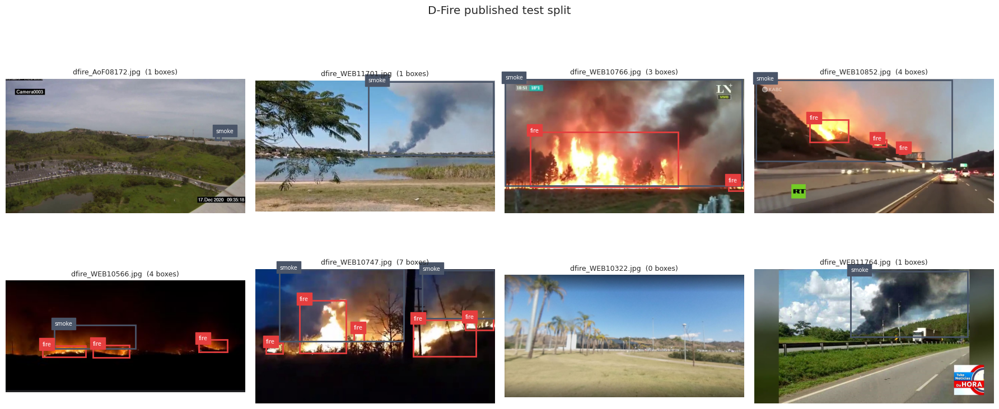

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/preview_published_test.png


In [13]:
pool_preview = []
test_preview = []
for record in STAGED:
    if record["folder"] == "pool":
        pool_preview.append(record["image"])
    else:
        test_preview.append(record["image"])

preview_images(pool_preview, "D-Fire published train split", "preview_published_train")
preview_images(test_preview, "D-Fire published test split", "preview_published_test")

### 3.2 Per image type

One row per image type, four random training images each. The background row matters as much as the others: D-Fire includes sunsets, lamps, and fog on purpose, and these are the images that teach the model not to raise a false alarm.

,training images
image type,
fire only,944
smoke only,4681
fire and smoke,3763
background,7833


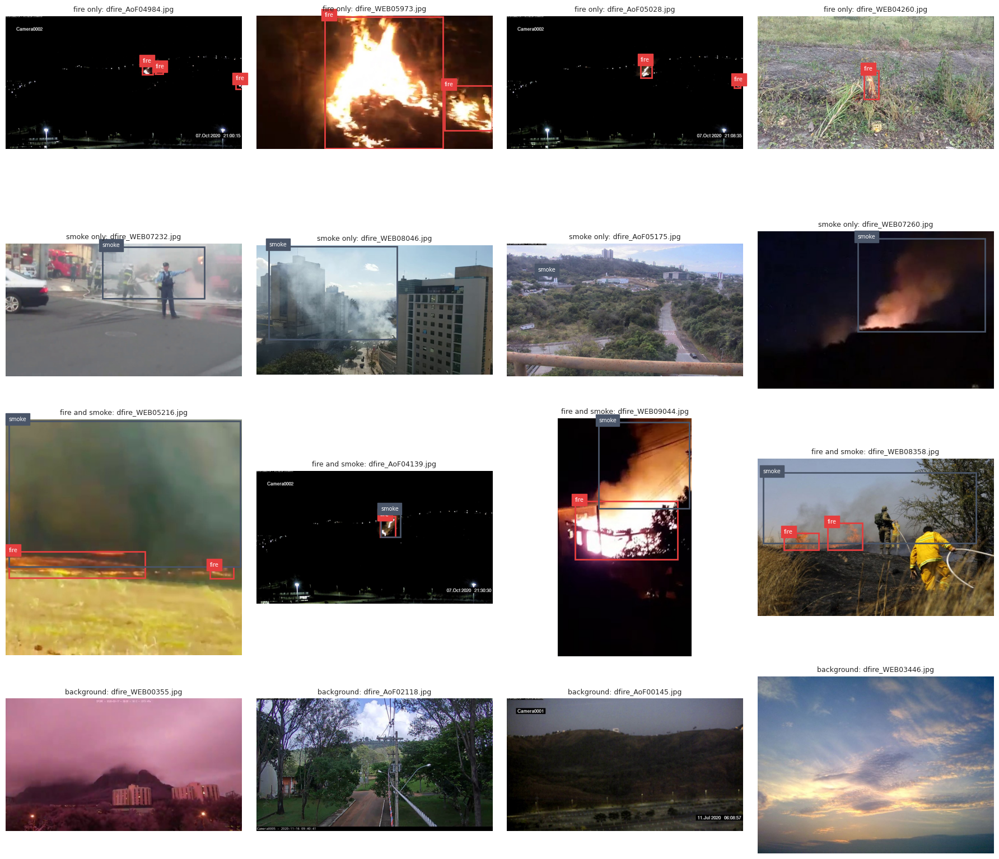

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/preview_by_image_type.png


In [14]:
images_by_type = {}
for image_type in IMAGE_TYPES:
    images_by_type[image_type] = []
for record in STAGED:
    if record["folder"] != "pool":
        continue
    counts = boxes_per_class(read_labels(label_path_for(record["image"])))
    images_by_type[image_type_of(counts["fire"], counts["smoke"])].append(record["image"])

type_rows = []
for image_type in IMAGE_TYPES:
    type_rows.append({"image type": image_type, "training images": len(images_by_type[image_type])})
display(pd.DataFrame(type_rows).set_index("image type"))

fig, axes = plt.subplots(len(IMAGE_TYPES), 4, figsize=(18, 4.2 * len(IMAGE_TYPES)))
for row_number, image_type in enumerate(IMAGE_TYPES):
    picks = list(images_by_type[image_type])
    random.Random(SEED).shuffle(picks)
    for column_number in range(4):
        ax = axes[row_number, column_number]
        ax.axis("off")
        if column_number >= len(picks):
            continue
        image_path = picks[column_number]
        draw_boxes(ax, image_path, read_labels(label_path_for(image_path)), title=f"{image_type}: {image_path.name[:24]}")
plt.tight_layout()
save_figure(fig, "preview_by_image_type")

## 4. Remove duplicates and near-duplicates

Many D-Fire images are frames cut from videos, so the same scene appears many times with tiny changes. If one of those frames is in training and the next one is in test, the test score measures memory, not detection.

Each image gets a difference hash: it is shrunk to 9 by 8 grey pixels, and each of the 64 bits records whether a pixel is brighter than its right-hand neighbour. Two images whose hashes differ in at most `NEAR_DUP_BITS` bits are treated as near-duplicates. Test has priority over training:

1. A repeat inside test (identical hash) is removed, keeping the first copy.
2. A training image identical to, or a near-duplicate of, any test image is removed.
3. A repeat inside the training pool (identical hash) is removed, keeping the first copy.

Near-duplicates inside the training pool are kept, but grouped in 4.3 so that a group never straddles train and val.

In [15]:
for record in STAGED:
    record["hash"] = difference_hash(record["image"])

DROPPED = []

test_records = []
test_seen = set()
pool_candidates = []
for record in STAGED:
    if record["folder"] == "pool":
        pool_candidates.append(record)
        continue
    if record["hash"] in test_seen:
        DROPPED.append({"record": record, "reason": "repeat inside test", "match": None, "distance": 0})
        continue
    test_seen.add(record["hash"])
    test_records.append(record)

test_hashes = []
for record in test_records:
    test_hashes.append(record["hash"])
pool_hashes = []
for record in pool_candidates:
    pool_hashes.append(record["hash"])
test_bits = stack_hash_bits(test_hashes)
candidate_bits = stack_hash_bits(pool_hashes)

closest_test = {}
for pool_index, test_index, distance in near_duplicate_pairs(candidate_bits, test_bits, NEAR_DUP_BITS):
    current = closest_test.get(pool_index)
    if current is None or distance < current[1]:
        closest_test[pool_index] = (test_index, distance)

pool_records = []
pool_seen = set()
for pool_index, record in enumerate(pool_candidates):
    if pool_index in closest_test:
        test_index, distance = closest_test[pool_index]
        if distance == 0:
            reason = "same as a test image"
        else:
            reason = "near-duplicate of a test image"
        DROPPED.append({"record": record, "reason": reason, "match": test_records[test_index], "distance": distance})
        continue
    if record["hash"] in pool_seen:
        DROPPED.append({"record": record, "reason": "repeat inside the training pool", "match": None, "distance": 0})
        continue
    pool_seen.add(record["hash"])
    pool_records.append(record)

removed_counts = Counter()
for item in DROPPED:
    removed_counts[(item["record"]["folder"], item["reason"])] += 1
removed_rows = []
for key, count in sorted(removed_counts.items()):
    removed_rows.append({"folder": key[0], "reason": key[1], "images removed": count})
if removed_rows:
    save_table(pd.DataFrame(removed_rows).set_index(["folder", "reason"]), "duplicates_removed")
else:
    display(pd.DataFrame([{"result": "No duplicates found"}]))

before_after = pd.DataFrame([
    {"folder": "pool", "before": len(pool_candidates), "after": len(pool_records)},
    {"folder": "test", "before": len(STAGED) - len(pool_candidates), "after": len(test_records)},
]).set_index("folder")
before_after["removed"] = before_after["before"] - before_after["after"]
save_table(before_after, "duplicates_before_after")

images removed
folder reason                                         
pool   near-duplicate of a test image             4371
       repeat inside the training pool             185
       same as a test image                       2410
test   repeat inside test                          365

,before,after,removed
folder,,,
pool,17221,10255,6966
test,4306,3941,365


### 4.1 What a near-duplicate looks like

The top row shows training images that were removed, the bottom row the test image each one matched. The pairs with the largest bit difference are shown, because they are the closest to the cut-off: if these still look like the same scene, `NEAR_DUP_BITS` is not too strict.

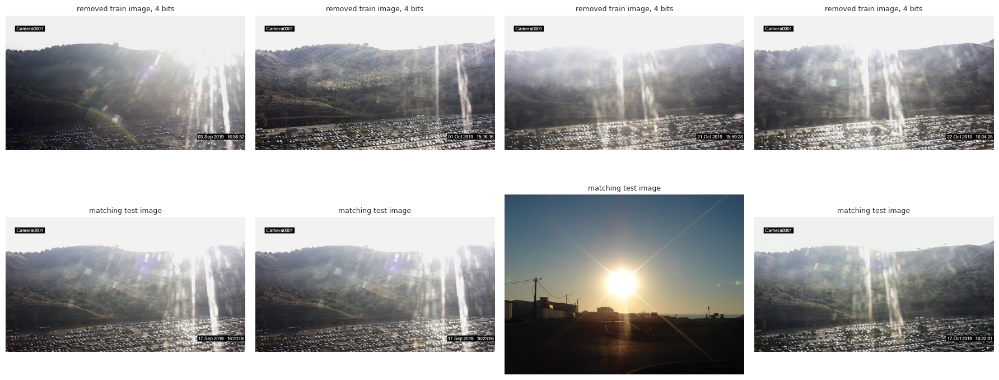

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/duplicates_near_pairs.png


In [16]:
def distance_of(item):
    return item["distance"]


near_pairs_found = []
for item in DROPPED:
    if item["match"] is not None and item["distance"] > 0:
        near_pairs_found.append(item)
near_pairs_found = sorted(near_pairs_found, key=distance_of, reverse=True)

if not near_pairs_found:
    display(pd.DataFrame([{"result": "No near-duplicates of test images were found"}]))
else:
    shown = near_pairs_found[:4]
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax in axes.flatten():
        ax.axis("off")
    for column_number, item in enumerate(shown):
        removed_image = item["record"]["image"]
        test_image = item["match"]["image"]
        draw_boxes(axes[0, column_number], removed_image, read_labels(label_path_for(removed_image)),
                   title=f"removed train image, {item['distance']} bits")
        draw_boxes(axes[1, column_number], test_image, read_labels(label_path_for(test_image)),
                   title="matching test image")
    plt.tight_layout()
    save_figure(fig, "duplicates_near_pairs")

The removed images are now deleted from the staging folder.

In [17]:
for item in DROPPED:
    image_path = item["record"]["image"]
    image_path.unlink(missing_ok=True)
    label_path_for(image_path).unlink(missing_ok=True)

STAGED = test_records + pool_records
print("Images kept:", len(STAGED))

Images kept: 14196


### 4.2 Near-duplicate groups inside the training pool

Training images whose hashes differ in at most `NEAR_DUP_BITS` bits are joined into one group, and groups that share an image are merged. A group is most often a run of frames from one video. The val split in section 5 takes whole groups, so the model is never scored on a frame whose neighbour it trained on.

In [18]:
pool_hashes = []
for record in pool_records:
    pool_hashes.append(record["hash"])
pool_bits = stack_hash_bits(pool_hashes)
pool_pairs = near_duplicate_pairs(pool_bits, pool_bits, NEAR_DUP_BITS, same_set=True)

parent = list(range(len(pool_records)))
for first, second, distance in pool_pairs:
    join_groups(parent, first, second)
for index, record in enumerate(pool_records):
    record["group"] = find_root(parent, index)
for record in test_records:
    record["group"] = -1

group_sizes = Counter()
for record in pool_records:
    group_sizes[record["group"]] += 1

sizes = np.array(list(group_sizes.values()))
group_summary = pd.DataFrame([
    {"measure": "near-duplicate pairs found", "value": len(pool_pairs)},
    {"measure": "groups", "value": len(sizes)},
    {"measure": "groups with one image", "value": int((sizes == 1).sum())},
    {"measure": "groups with two or more images", "value": int((sizes > 1).sum())},
    {"measure": "images in groups of two or more", "value": int(sizes[sizes > 1].sum())},
    {"measure": "largest group", "value": int(sizes.max())},
]).set_index("measure")
save_table(group_summary, "duplicates_group_summary")

,value
measure,
near-duplicate pairs found,1308
groups,9336
groups with one image,8865
groups with two or more images,471
images in groups of two or more,1390
largest group,16


Group sizes, and four images from the largest group. A long tail of big groups means the dataset has fewer truly different scenes than its image count suggests.

,groups
group size,
1,8865
2,274
3 to 5,160
6 to 10,34
11 to 50,3
over 50,0


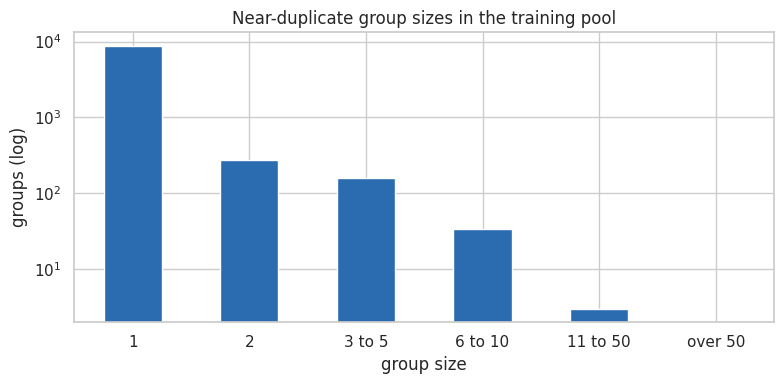

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/duplicates_group_sizes.png


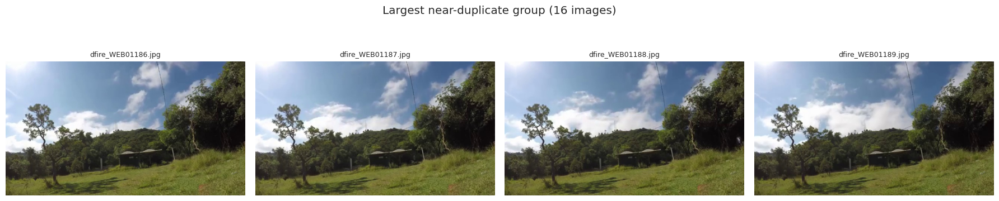

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/duplicates_largest_group.png


In [19]:
top_edge = max(int(np.max(sizes)) + 1, 51)
size_bins = [0, 1, 2, 5, 10, 50, top_edge]
size_labels = ["1", "2", "3 to 5", "6 to 10", "11 to 50", "over 50"]
binned_sizes = pd.cut(pd.Series(sizes), bins=size_bins, labels=size_labels)
size_table = binned_sizes.value_counts().reindex(size_labels, fill_value=0).to_frame("groups")
size_table.index.name = "group size"
save_table(size_table, "duplicates_group_sizes")

fig, ax = plt.subplots(figsize=(8, 4))
size_table["groups"].plot(kind="bar", ax=ax, color="#2b6cb0")
ax.set_yscale("log")
ax.set_ylabel("groups (log)")
ax.set_title("Near-duplicate group sizes in the training pool")
plt.xticks(rotation=0)
plt.tight_layout()
save_figure(fig, "duplicates_group_sizes")

largest_group = group_sizes.most_common(1)[0][0]
largest_members = []
for record in pool_records:
    if record["group"] == largest_group:
        largest_members.append(record["image"])
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax in axes:
    ax.axis("off")
for ax, image_path in zip(axes, largest_members[:4]):
    draw_boxes(ax, image_path, read_labels(label_path_for(image_path)), title=image_path.name[:30])
fig.suptitle(f"Largest near-duplicate group ({len(largest_members)} images)")
plt.tight_layout()
save_figure(fig, "duplicates_largest_group")

## 5. One table of every image, and the fixed val and test splits

Two DataFrames are built here and used by everything after this point:

- `manifest`: one row per image, with its split, near-duplicate group, size, brightness, colour statistics, number of boxes, a count column for each class, and its image type.
- `boxes`: one row per box, with its class, position, size, and aspect ratio.

Two colour features are added because they relate directly to the task. `warm_share` is the share of pixels that look like flame (bright red, red above green above blue). `grey_share` is the share of pixels that look like smoke or haze (low saturation, mid to high brightness). They are measured on a 64 by 64 thumbnail.

In [20]:
manifest_rows = []
box_rows = []
for record in STAGED:
    image_path = record["image"]
    with Image.open(image_path) as image:
        width, height = image.size
        thumbnail = image.convert("RGB").resize((64, 64))
    rgb = np.asarray(thumbnail, dtype=np.float32)
    grey = np.asarray(thumbnail.convert("L"), dtype=np.float32)
    hsv = np.asarray(thumbnail.convert("HSV"), dtype=np.float32)
    red = rgb[:, :, 0]
    green = rgb[:, :, 1]
    blue = rgb[:, :, 2]
    warm_pixels = (red >= 180) & (red > green) & (green > blue)
    grey_pixels = (hsv[:, :, 1] < 40) & (hsv[:, :, 2] > 100) & (hsv[:, :, 2] < 230)

    rows = read_labels(label_path_for(image_path))
    class_counts = boxes_per_class(rows)
    if record["folder"] == "test":
        split = "test"
    else:
        split = "train"

    entry = {
        "image": str(image_path),
        "original_name": record["original_name"],
        "prefix": name_prefix(record["original_name"]),
        "folder": record["folder"],
        "split": split,
        "group": record["group"],
        "hash": record["hash"],
        "file_sha1": hashlib.sha1(image_path.read_bytes()).hexdigest(),
        "width": width,
        "height": height,
        "brightness": float(grey.mean()),
        "contrast": float(grey.std()),
        "mean_r": float(red.mean()),
        "mean_g": float(green.mean()),
        "mean_b": float(blue.mean()),
        "saturation": float(hsv[:, :, 1].mean()),
        "warm_share": float(warm_pixels.mean()),
        "grey_share": float(grey_pixels.mean()),
        "boxes": len(rows),
    }
    for class_name in CLASS_ORDER:
        entry[class_name] = int(class_counts[class_name])
    entry["image_type"] = image_type_of(entry["fire"], entry["smoke"])

    areas = []
    aspects = []
    centers_x = []
    centers_y = []
    for class_id, xc, yc, w, h in rows:
        box_w_px = w * width
        box_h_px = h * height
        aspect = box_w_px / max(box_h_px, 1e-6)
        areas.append(w * h)
        aspects.append(aspect)
        centers_x.append(xc)
        centers_y.append(yc)
        box_rows.append({
            "image": str(image_path),
            "group": record["group"],
            "class": CLASS_NAMES[class_id],
            "xc": xc,
            "yc": yc,
            "w": w,
            "h": h,
            "rel_area": w * h,
            "box_w_px": box_w_px,
            "box_h_px": box_h_px,
            "aspect": aspect,
            "size": size_bucket(w, h, width, height, IMGSZ_BASE),
            "size_large": size_bucket(w, h, width, height, IMGSZ_LARGE),
        })

    if areas:
        entry["mean_box_area"] = float(np.mean(areas))
        entry["mean_aspect"] = float(np.mean(aspects))
        entry["mean_xc"] = float(np.mean(centers_x))
        entry["mean_yc"] = float(np.mean(centers_y))
    else:
        entry["mean_box_area"] = 0.0
        entry["mean_aspect"] = 0.0
        entry["mean_xc"] = 0.5
        entry["mean_yc"] = 0.5
    manifest_rows.append(entry)

manifest = pd.DataFrame(manifest_rows)
boxes = pd.DataFrame(box_rows)
display(manifest.head())
display(boxes.head())

,image,original_name,prefix,folder,split,group,hash,file_sha1,width,height,brightness,contrast,mean_r,mean_g,mean_b,saturation,warm_share,grey_share,boxes,fire,smoke,image_type,mean_box_area,mean_aspect,mean_xc,mean_yc
0,/content/SAMS/datasets/vision/hazard/merged/im...,AoF06723.jpg,AoF,test,test,-1,c0d00623c08cdecf,c70ab2710d9fdb32403cdc495475db358cd50edc,1280,720,86.105469,67.012886,84.152832,86.046387,91.538574,46.956787,0.000244,0.197266,0,0,0,background,0.0,0.0,0.5,0.5
1,/content/SAMS/datasets/vision/hazard/merged/im...,AoF06724.jpg,AoF,test,test,-1,ccc3266c0c61e8e0,442dd32bd5d6792f53285d4330dbb8c176e8517e,1270,685,112.319580,54.366047,113.624268,112.334717,108.824707,45.377197,0.000488,0.349365,0,0,0,background,0.0,0.0,0.5,0.5
2,/content/SAMS/datasets/vision/hazard/merged/im...,AoF06725.jpg,AoF,test,test,-1,e7e02604006168c0,e29c182e3e6184d1f4d21b840822cc9b5f57c080,1267,702,105.834717,60.988476,108.187744,105.493652,101.483643,39.531982,0.000244,0.327393,0,0,0,background,0.0,0.0,0.5,0.5
3,/content/SAMS/datasets/vision/hazard/merged/im...,AoF06726.jpg,AoF,test,test,-1,fff1020e746168e0,6d198d06f05f63e020e0e151513d1ac55ea87868,1278,712,103.737305,57.474373,105.260498,103.718262,99.841553,45.750732,0.000732,0.295166,0,0,0,background,0.0,0.0,0.5,0.5
4,/content/SAMS/datasets/vision/hazard/merged/im...,AoF06727.jpg,AoF,test,test,-1,c6193bff13ebdbdc,523b201319f76fbebd82399a5189ddc22dbbd0a0,1276,717,117.782715,59.363605,117.732666,117.774170,117.948486,27.829346,0.001709,0.434082,0,0,0,background,0.0,0.0,0.5,0.5


,image,group,class,xc,yc,w,h,rel_area,box_w_px,box_h_px,aspect,size,size_large
0,/content/SAMS/datasets/vision/hazard/merged/im...,-1,smoke,0.951172,0.185417,0.057031,0.093056,0.005307,72.99968,67.00032,1.089542,medium,medium
1,/content/SAMS/datasets/vision/hazard/merged/im...,-1,smoke,0.332422,0.402083,0.028906,0.031944,0.000923,36.99968,22.99968,1.608704,small,small
2,/content/SAMS/datasets/vision/hazard/merged/im...,-1,smoke,0.357813,0.359028,0.040625,0.040278,0.001636,52.00000,29.00016,1.793094,small,small
3,/content/SAMS/datasets/vision/hazard/merged/im...,-1,fire,0.743359,0.649306,0.130469,0.112500,0.014678,167.00032,81.00000,2.061732,medium,medium
4,/content/SAMS/datasets/vision/hazard/merged/im...,-1,fire,0.461328,0.610417,0.047656,0.098611,0.004699,60.99968,70.99992,0.859151,medium,medium


### 5.1 How val and test are fixed

- **Test** is every published test image that survived cleaning. It is scored once, in section 13.
- **Val** is carved out of the published train split with seed `SEED` (42): whole near-duplicate groups are drawn at random until val holds `VAL_FRACTION` (85/15 train/val on the published train pool). A group is never split. The published test split is never used for val.
- If a class still has fewer than `MIN_EVAL_BOXES` boxes in val, more whole groups that contain that class are moved into val. No copies are made.
- Everything left in the pool is the training split.

In [21]:
pool_frame = manifest[manifest["folder"] == "pool"]
group_members = {}
for index, group_id in zip(pool_frame.index, pool_frame["group"]):
    if group_id not in group_members:
        group_members[group_id] = []
    group_members[group_id].append(index)

group_ids = sorted(group_members)
rng = np.random.default_rng(SEED)
shuffled_groups = []
for position in rng.permutation(len(group_ids)):
    shuffled_groups.append(group_ids[int(position)])

target_val_images = int(round(VAL_FRACTION * len(pool_frame)))
val_index = []
val_groups = set()
for group_id in shuffled_groups:
    if len(val_index) >= target_val_images:
        break
    val_index.extend(group_members[group_id])
    val_groups.add(group_id)
manifest.loc[val_index, "split"] = "val"

group_class_totals = pool_frame.groupby("group")[CLASS_ORDER].sum()
topup_rows = []
for class_name in CLASS_ORDER:
    in_val = int(manifest.loc[manifest["split"] == "val", class_name].sum())
    added_groups = 0
    added_images = 0
    if in_val < MIN_EVAL_BOXES:
        for group_id in shuffled_groups:
            if in_val >= MIN_EVAL_BOXES:
                break
            if group_id in val_groups:
                continue
            if group_class_totals.loc[group_id, class_name] == 0:
                continue
            manifest.loc[group_members[group_id], "split"] = "val"
            val_groups.add(group_id)
            in_val += int(group_class_totals.loc[group_id, class_name])
            added_groups += 1
            added_images += len(group_members[group_id])
    topup_rows.append({
        "class": class_name,
        "val boxes after top-up": in_val,
        "groups added": added_groups,
        "images added": added_images,
    })
save_table(pd.DataFrame(topup_rows).set_index("class"), "val_top_up")

split_of_image = dict(zip(manifest["image"], manifest["split"]))
boxes["split"] = boxes["image"].map(split_of_image)

TRAIN_POOL_IMAGES = []
for image_path in manifest.loc[manifest["split"] == "train", "image"]:
    TRAIN_POOL_IMAGES.append(Path(image_path))
VAL_IMAGES = []
for image_path in manifest.loc[manifest["split"] == "val", "image"]:
    VAL_IMAGES.append(Path(image_path))
TEST_IMAGES = []
for image_path in manifest.loc[manifest["split"] == "test", "image"]:
    TEST_IMAGES.append(Path(image_path))

VAL_LIST = write_list("val", VAL_IMAGES)
TEST_LIST = write_list("test", TEST_IMAGES)

list_rows = [
    {"split": "train", "images": len(TRAIN_POOL_IMAGES), "file": "written in section 8"},
    {"split": "val", "images": len(VAL_IMAGES), "file": str(VAL_LIST)},
    {"split": "test", "images": len(TEST_IMAGES), "file": str(TEST_LIST)},
]
save_table(pd.DataFrame(list_rows).set_index("split"), "split_sizes")

,val boxes after top-up,groups added,images added
class,,,
fire,1507,0,0
smoke,1006,0,0


,images,file
split,,
train,8717,written in section 8
val,1538,/content/SAMS/datasets/vision/hazard/merged/li...
test,3941,/content/SAMS/datasets/vision/hazard/merged/li...


### 5.2 Leakage checks

Every pair of splits is compared four ways. All counts must be zero, otherwise the notebook stops:

| Check | Meaning |
|-------|---------|
| identical files | the same file bytes (SHA-1) in both splits |
| identical hashes | the same 64-bit difference hash in both splits |
| near-duplicates | hashes that differ in at most `NEAR_DUP_BITS` bits |
| shared groups | a near-duplicate group with members in both splits |

In [22]:
def leakage_row(name_a, frame_a, name_b, frame_b):
    bits_a = stack_hash_bits(frame_a["hash"])
    bits_b = stack_hash_bits(frame_b["hash"])
    pairs = near_duplicate_pairs(bits_a, bits_b, NEAR_DUP_BITS)
    identical_hashes = 0
    for pair in pairs:
        if pair[2] == 0:
            identical_hashes += 1
    identical_files = len(set(frame_a["file_sha1"]) & set(frame_b["file_sha1"]))
    groups_a = set(frame_a.loc[frame_a["group"] >= 0, "group"])
    groups_b = set(frame_b.loc[frame_b["group"] >= 0, "group"])
    shared_groups = len(groups_a & groups_b)
    row = {
        "splits": f"{name_a} vs {name_b}",
        "identical files": identical_files,
        "identical hashes": identical_hashes,
        "near-duplicates": len(pairs),
        "shared groups": shared_groups,
    }
    row["passed"] = identical_files + len(pairs) + shared_groups == 0
    return row


split_frames = {}
for split_name in ["train", "val", "test"]:
    split_frames[split_name] = manifest[manifest["split"] == split_name]

leakage_rows = [
    leakage_row("train", split_frames["train"], "val", split_frames["val"]),
    leakage_row("train", split_frames["train"], "test", split_frames["test"]),
    leakage_row("val", split_frames["val"], "test", split_frames["test"]),
]
leakage_table = pd.DataFrame(leakage_rows).set_index("splits")
save_table(leakage_table, "leakage_checks")
if not leakage_table["passed"].all():
    raise RuntimeError("A leakage check failed. See the table above.")
print("All leakage checks passed.")

,identical files,identical hashes,near-duplicates,shared groups,passed
splits,,,,,
train vs val,0,0,0,0,True
train vs test,0,0,0,0,True
val vs test,0,0,0,0,True


All leakage checks passed.


### 5.3 Are val and test large enough, and do they look like training?

The first table checks that each class has enough real boxes to be scored. A class marked `False` will have a noisy score, and the fix is more real images, not copies. The second table shows the share of each image type per split. Large differences mean val would reward a different balance of fire, smoke, and background than test.

In [23]:
eval_table = pd.DataFrame(index=CLASS_ORDER)
eval_table.index.name = "class"
for split_name in ["train", "val", "test"]:
    subset = manifest[manifest["split"] == split_name]
    box_column = []
    image_column = []
    for class_name in CLASS_ORDER:
        box_column.append(int(subset[class_name].sum()))
        image_column.append(int((subset[class_name] > 0).sum()))
    eval_table[f"{split_name} boxes"] = box_column
    eval_table[f"{split_name} images"] = image_column
eval_table["val has enough"] = eval_table["val boxes"] >= MIN_EVAL_BOXES
eval_table["test has enough"] = eval_table["test boxes"] >= MIN_EVAL_BOXES
save_table(eval_table, "eval_split_sufficiency")

type_share = pd.crosstab(manifest["image_type"], manifest["split"], normalize="columns") * 100
type_share = type_share.reindex(index=IMAGE_TYPES, columns=["train", "val", "test"], fill_value=0)
save_table(type_share.round(1), "split_image_type_share_percent")

,train boxes,train images,val boxes,val images,test boxes,test images,val has enough,test has enough
class,,,,,,,,
fire,8360,3034,1507,543,2783,1045,True,True
smoke,5776,5023,1006,866,2153,1935,True,True


split,train,val,test
image_type,,,
fire only,5.0,5.4,4.9
smoke only,27.8,26.4,27.5
fire and smoke,29.8,29.9,21.6
background,37.4,38.3,46.0


### 5.4 Preview of val and test

Eight random images from each fixed split, with all their labels. These are the images every experiment is scored on.

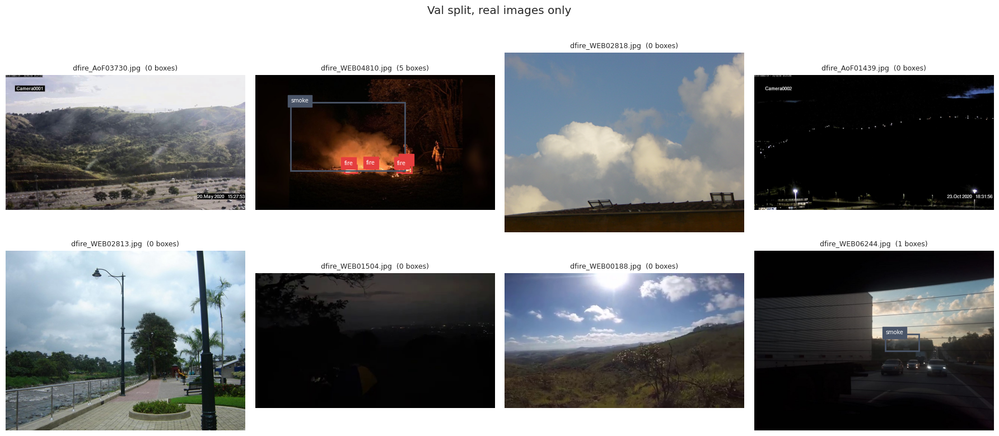

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/preview_val.png


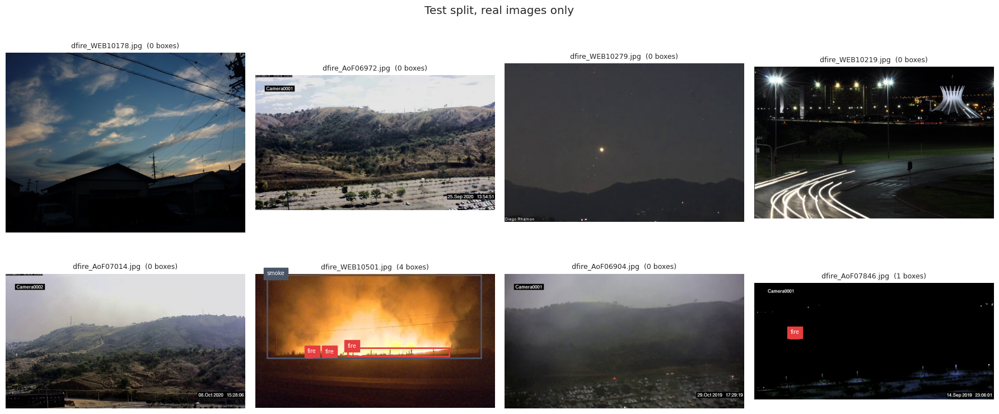

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/preview_test.png


In [24]:
preview_images(VAL_IMAGES, "Val split, real images only", "preview_val")
preview_images(TEST_IMAGES, "Test split, real images only", "preview_test")

## 6. Exploratory data analysis

The EDA answers six questions before any training:

1. How many images of each type are in each split?
2. Which class is rarer, by boxes and by images?
3. How big are the boxes? Distant fires are expected to be small, smoke plumes large.
4. Where do fire and smoke sit in the frame, and is that the same in train and test?
5. How do images with fire differ from background images in brightness and colour, and which background images are fire-like?
6. Is either class rare enough in the training split that train-only augmentation is needed?

Unless a cell says otherwise, the EDA uses all three splits.

### 6.1 Images per split and image type

The bars show how many images of each type each split holds. Look at the background bar: D-Fire has a large share of images with no fire and no smoke, which is good for false alarms but means fewer images per class.

split,train,val,test,total
image_type,,,,
fire only,437,83,193,713
smoke only,2426,406,1083,3915
fire and smoke,2597,460,852,3909
background,3257,589,1813,5659


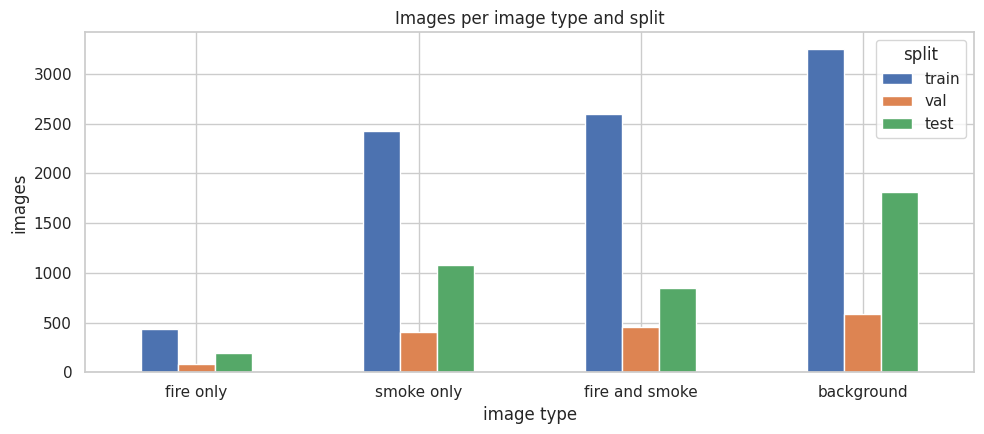

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/eda_images_per_type_split.png


In [25]:
split_order = ["train", "val", "test"]
type_table = pd.crosstab(manifest["image_type"], manifest["split"])
type_table = type_table.reindex(index=IMAGE_TYPES, columns=split_order, fill_value=0)
type_table["total"] = type_table.sum(axis=1)
save_table(type_table, "eda_images_per_type_split")

fig, ax = plt.subplots(figsize=(10, 4.5))
type_table.drop(columns="total").plot(kind="bar", ax=ax)
ax.set_title("Images per image type and split")
ax.set_xlabel("image type")
ax.set_ylabel("images")
plt.xticks(rotation=0)
plt.tight_layout()
save_figure(fig, "eda_images_per_type_split")

### 6.2 Boxes per class and split

The table counts boxes, not images. Fire often comes as several small boxes per image, smoke as one large plume, so the rarer class by images may not be the rarer class by boxes. Balancing in section 8 works on boxes.

split,train,val,test,total
class,,,,
fire,8360,1507,2783,12650
smoke,5776,1006,2153,8935


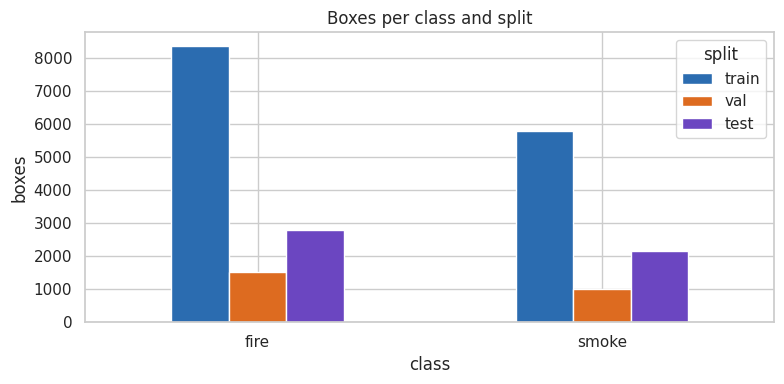

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/eda_boxes_per_class_split.png


In [26]:
class_split = pd.crosstab(boxes["class"], boxes["split"])
class_split = class_split.reindex(index=CLASS_ORDER, columns=split_order, fill_value=0)
class_split["total"] = class_split.sum(axis=1)
save_table(class_split, "eda_boxes_per_class_split")

fig, ax = plt.subplots(figsize=(8, 4))
class_split.drop(columns="total").plot(kind="bar", ax=ax, color=["#2b6cb0", "#dd6b20", "#6b46c1"])
ax.set_title("Boxes per class and split")
ax.set_ylabel("boxes")
plt.xticks(rotation=0)
plt.tight_layout()
save_figure(fig, "eda_boxes_per_class_split")

### 6.3 Boxes per image

For images that contain a class, how many boxes of that class they hold. Many boxes per image makes balancing uneven: copying one such image adds many boxes at once.

,images,mean boxes,median boxes,75th percentile,max boxes
class,,,,,
fire,4622,2.74,2.0,4.0,22.0
smoke,7824,1.14,1.0,1.0,10.0


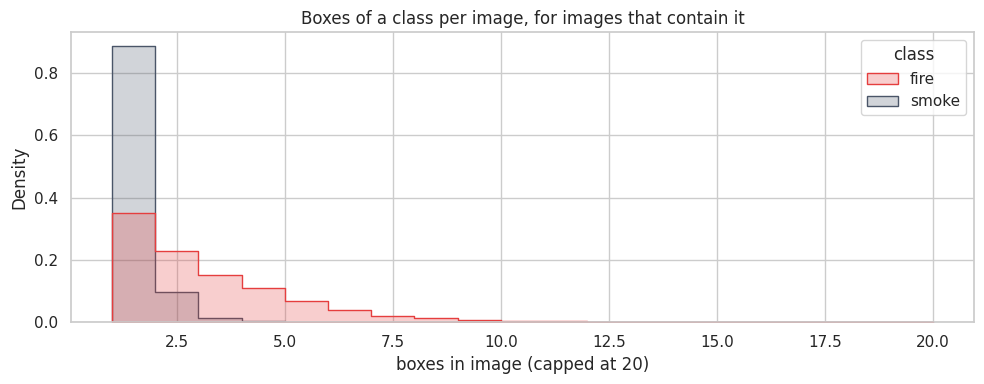

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/eda_boxes_per_image.png


In [27]:
per_image_rows = []
per_image_parts = []
for class_name in CLASS_ORDER:
    with_class = manifest[manifest[class_name] > 0]
    stats = with_class[class_name].describe()
    per_image_rows.append({
        "class": class_name,
        "images": int(stats["count"]),
        "mean boxes": stats["mean"],
        "median boxes": stats["50%"],
        "75th percentile": stats["75%"],
        "max boxes": stats["max"],
    })
    part = pd.DataFrame({"class": class_name, "boxes in image (capped at 20)": with_class[class_name].clip(upper=20)})
    per_image_parts.append(part)
save_table(pd.DataFrame(per_image_rows).set_index("class").round(2), "eda_boxes_per_image")

per_image_plot = pd.concat(per_image_parts, ignore_index=True)
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=per_image_plot, x="boxes in image (capped at 20)", hue="class", binwidth=1,
             stat="density", common_norm=False, element="step", ax=ax,
             palette={"fire": "#e53e3e", "smoke": "#4a5568"})
ax.set_title("Boxes of a class per image, for images that contain it")
plt.tight_layout()
save_figure(fig, "eda_boxes_per_image")

### 6.4 Box size

Box area is shown as a share of the image area, on a log scale. The size table uses the COCO convention after the image is resized for training: small is under 32 by 32 pixels, medium is under 96 by 96, large is anything bigger. It is shown at `IMGSZ_BASE` and at `IMGSZ_LARGE`. A large share of small fire boxes at the base size is the reason experiment E2 always trains at `IMGSZ_LARGE` as well, because a small, distant fire is the one that matters most to catch early.

/tmp/ipykernel_3245/535663885.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_boxes, x="class", y="rel_area", order=CLASS_ORDER, showfliers=False, ax=ax,


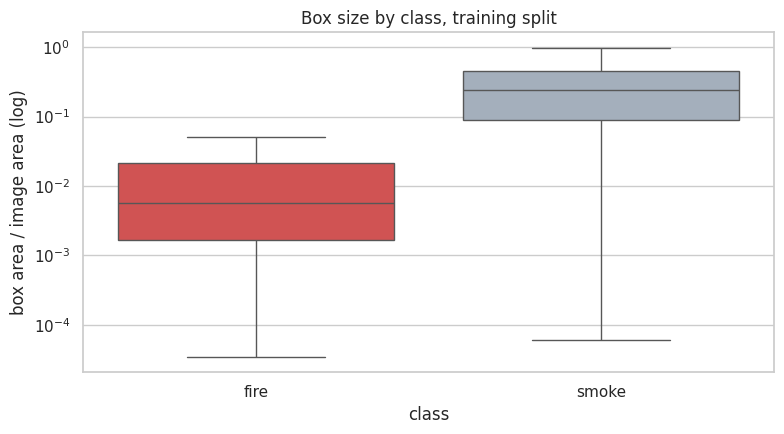

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/eda_box_area_by_class.png


,small at 640,medium at 640,large at 640,small at 960,medium at 960,large at 960
class,,,,,,
fire,43.5,39.6,16.9,27.2,43.9,28.9
smoke,3.9,10.9,85.1,1.9,7.8,90.3


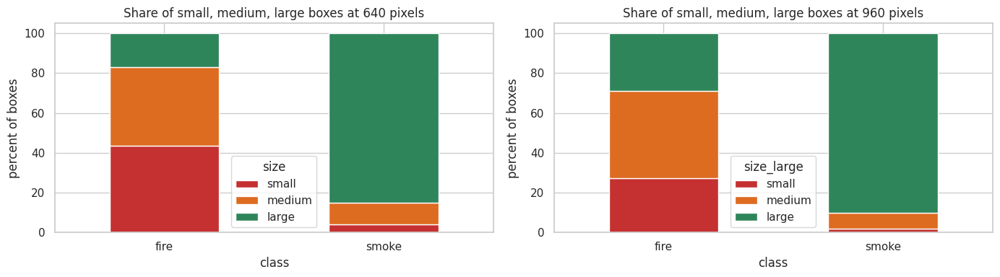

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/eda_box_size_share.png


In [28]:
train_boxes = boxes[boxes["split"] == "train"]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=train_boxes, x="class", y="rel_area", order=CLASS_ORDER, showfliers=False, ax=ax,
            palette={"fire": "#e53e3e", "smoke": "#a0aec0"})
ax.set_yscale("log")
ax.set_ylabel("box area / image area (log)")
ax.set_title("Box size by class, training split")
plt.tight_layout()
save_figure(fig, "eda_box_area_by_class")

size_order = ["small", "medium", "large"]
size_base = pd.crosstab(train_boxes["class"], train_boxes["size"], normalize="index") * 100
size_base = size_base.reindex(index=CLASS_ORDER, columns=size_order, fill_value=0)
size_large = pd.crosstab(train_boxes["class"], train_boxes["size_large"], normalize="index") * 100
size_large = size_large.reindex(index=CLASS_ORDER, columns=size_order, fill_value=0)
size_share = pd.DataFrame(index=CLASS_ORDER)
size_share.index.name = "class"
for size_name in size_order:
    size_share[f"{size_name} at {IMGSZ_BASE}"] = size_base[size_name]
for size_name in size_order:
    size_share[f"{size_name} at {IMGSZ_LARGE}"] = size_large[size_name]
save_table(size_share.round(1), "eda_box_size_share_percent")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
size_base.plot(kind="bar", stacked=True, ax=axes[0], color=["#c53030", "#dd6b20", "#2f855a"])
axes[0].set_title(f"Share of small, medium, large boxes at {IMGSZ_BASE} pixels")
size_large.plot(kind="bar", stacked=True, ax=axes[1], color=["#c53030", "#dd6b20", "#2f855a"])
axes[1].set_title(f"Share of small, medium, large boxes at {IMGSZ_LARGE} pixels")
for ax in axes:
    ax.set_ylabel("percent of boxes")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
save_figure(fig, "eda_box_size_share")

### 6.5 Box shape

Aspect ratio is width divided by height. Flames are usually taller than wide, smoke plumes often wider as they spread. A class whose shape varies a lot is harder to box tightly, which shows up as a lower mAP50-95 than mAP50. Smoke has no sharp edge at all, so its mAP50-95 is expected to be low even for a good model.

/tmp/ipykernel_3245/706308902.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_boxes, x="class", y="aspect", order=CLASS_ORDER, showfliers=False, ax=ax,


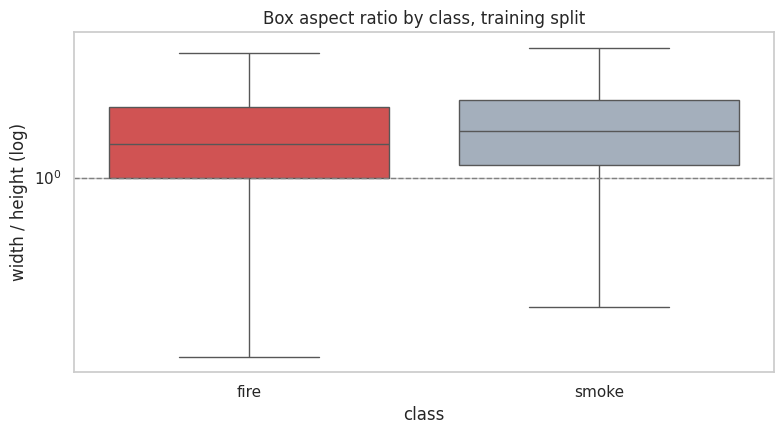

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/eda_box_aspect_by_class.png


,count,25%,50%,75%
class,,,,
fire,8360.0,1.00,1.44,2.12
smoke,5776.0,1.15,1.66,2.31


In [29]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=train_boxes, x="class", y="aspect", order=CLASS_ORDER, showfliers=False, ax=ax,
            palette={"fire": "#e53e3e", "smoke": "#a0aec0"})
ax.set_yscale("log")
ax.axhline(1.0, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("width / height (log)")
ax.set_title("Box aspect ratio by class, training split")
plt.tight_layout()
save_figure(fig, "eda_box_aspect_by_class")

aspect_table = train_boxes.groupby("class")["aspect"].describe()[["count", "25%", "50%", "75%"]]
save_table(aspect_table.reindex(CLASS_ORDER).round(2), "eda_box_aspect_by_class")

### 6.6 Where fire and smoke sit in the image

Each panel is a 2D histogram of box centers, with the top of the image at the top. Smoke is expected higher than fire, because it rises. Compare the train column with the test column: if they differ a lot, the test images are framed differently from the training images.

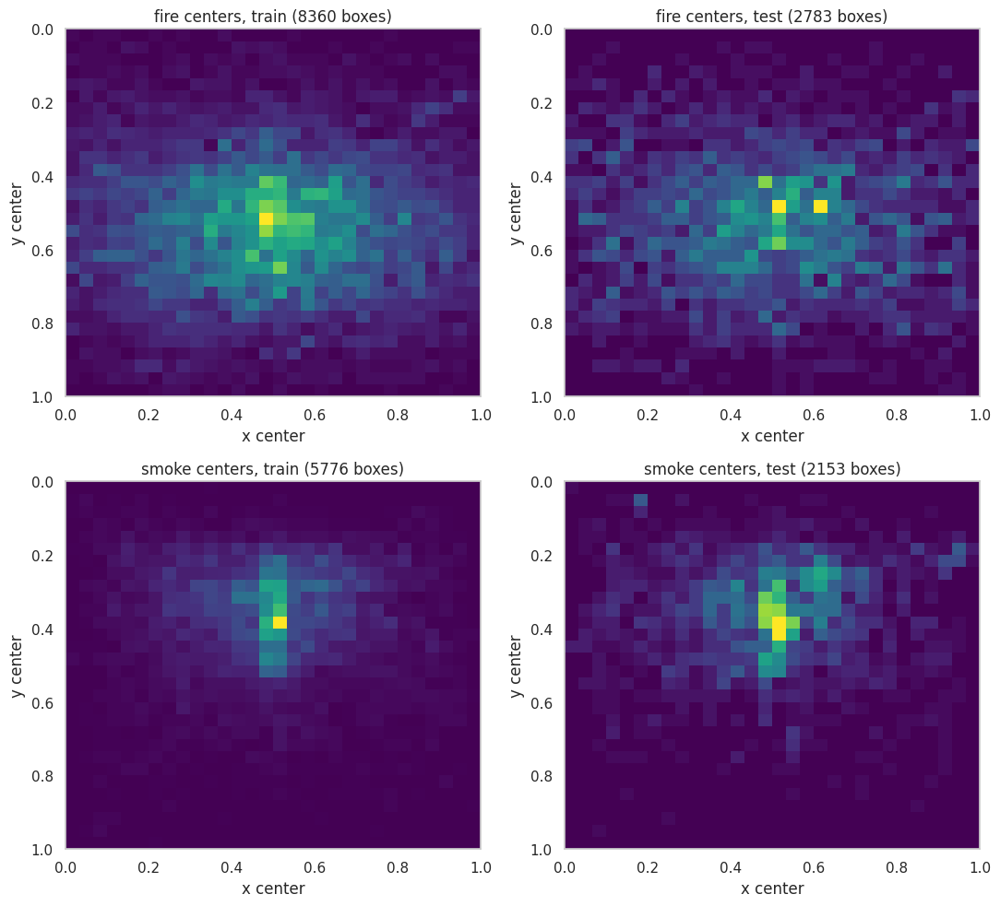

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/eda_box_center_heatmaps.png


In [30]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for row_number, class_name in enumerate(CLASS_ORDER):
    for column_number, split_name in enumerate(["train", "test"]):
        ax = axes[row_number, column_number]
        subset = boxes[(boxes["class"] == class_name) & (boxes["split"] == split_name)]
        if subset.empty:
            ax.set_title(f"{class_name}, {split_name}: no boxes")
            ax.axis("off")
            continue
        ax.hist2d(subset["xc"], subset["yc"], bins=30, range=[[0, 1], [0, 1]], cmap="viridis")
        ax.invert_yaxis()
        ax.set_title(f"{class_name} centers, {split_name} ({len(subset)} boxes)")
        ax.set_xlabel("x center")
        ax.set_ylabel("y center")
plt.tight_layout()
save_figure(fig, "eda_box_center_heatmaps")

### 6.7 Image resolution and brightness

The table and the left chart show image sizes per split. Many small images mean that `IMGSZ_LARGE` mostly upsamples, which can still help small boxes because the feature maps get finer, but adds no real detail. The right chart shows brightness per image type: night scenes with fire are bright spots on a dark frame, which is a different look from daytime smoke.

,images,median_width,median_height,min_width,max_width,mean_brightness,std_brightness
split,,,,,,,
train,8717,640.0,439.0,162,4035,100.5,38.0
val,1538,678.0,449.5,162,4288,98.7,39.0
test,3941,960.0,608.0,162,3840,94.7,38.9


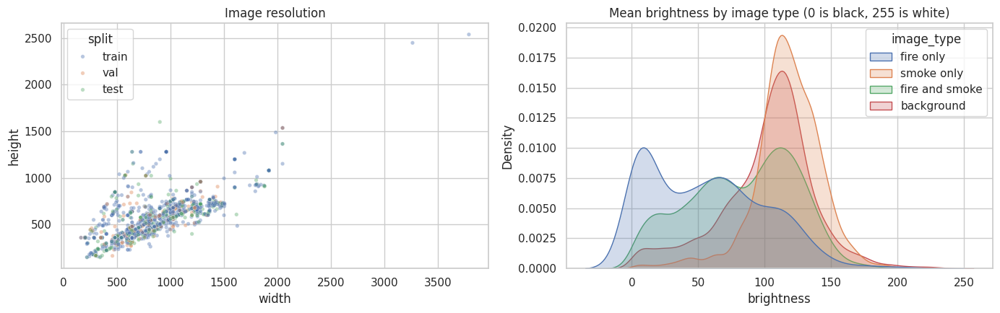

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/eda_resolution_brightness.png


In [31]:
look_table = manifest.groupby("split").agg(
    images=("image", "count"),
    median_width=("width", "median"),
    median_height=("height", "median"),
    min_width=("width", "min"),
    max_width=("width", "max"),
    mean_brightness=("brightness", "mean"),
    std_brightness=("brightness", "std"),
)
save_table(look_table.reindex(split_order).round(1), "eda_resolution_brightness")

plot_sample = manifest
if len(plot_sample) > 5000:
    plot_sample = manifest.sample(5000, random_state=SEED)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=plot_sample, x="width", y="height", hue="split", hue_order=split_order, alpha=0.4, s=15, ax=axes[0])
axes[0].set_title("Image resolution")
sns.kdeplot(data=manifest, x="brightness", hue="image_type", hue_order=IMAGE_TYPES, common_norm=False,
            fill=True, alpha=0.25, ax=axes[1])
axes[1].set_title("Mean brightness by image type (0 is black, 255 is white)")
plt.tight_layout()
save_figure(fig, "eda_resolution_brightness")

### 6.8 Colour: flame-coloured and haze-coloured pixels

`warm_share` should be highest in fire images and `grey_share` highest in smoke images. The useful part is the background box: background images with a high `warm_share` (sunsets, lamps, red objects) or a high `grey_share` (fog, clouds, steam) are the hard negatives. If the background distribution overlaps strongly with the fire or smoke one, colour alone cannot separate them, and the model has to learn shape and texture.

,warm_share,grey_share,saturation,contrast
image_type,,,,
fire only,0.074,0.070,93.885,41.557
smoke only,0.053,0.261,61.368,55.148
fire and smoke,0.089,0.137,93.558,48.862
background,0.045,0.196,73.161,55.911


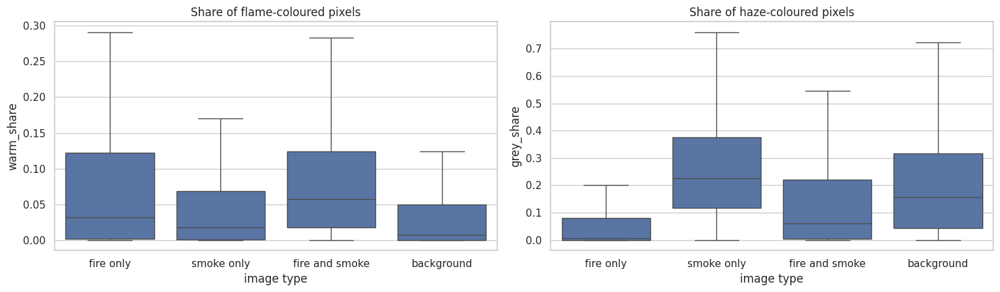

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/eda_colour_by_image_type.png


In [32]:
colour_table = manifest.groupby("image_type")[["warm_share", "grey_share", "saturation", "contrast"]].mean()
save_table(colour_table.reindex(IMAGE_TYPES).round(3), "eda_colour_by_image_type")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=manifest, x="image_type", y="warm_share", order=IMAGE_TYPES, showfliers=False, ax=axes[0])
axes[0].set_title("Share of flame-coloured pixels")
sns.boxplot(data=manifest, x="image_type", y="grey_share", order=IMAGE_TYPES, showfliers=False, ax=axes[1])
axes[1].set_title("Share of haze-coloured pixels")
for ax in axes:
    ax.set_xlabel("image type")
plt.tight_layout()
save_figure(fig, "eda_colour_by_image_type")

### 6.9 Which classes appear together

Each cell is the percent of training images containing the row class that also contain the column class. Balancing copies whole images, so if most smoke images also contain fire, copying smoke images raises the fire count too.

,fire,smoke
fire,100.0,85.6
smoke,51.7,100.0


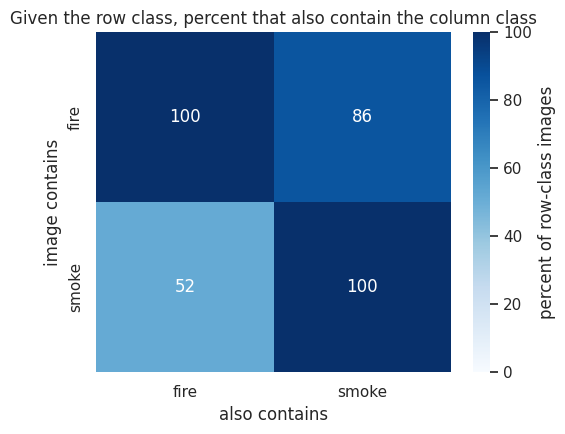

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/eda_class_cooccurrence.png


In [33]:
train_images = manifest[manifest["split"] == "train"]
presence = (train_images[CLASS_ORDER] > 0).astype(int)
together = presence.T.dot(presence)
images_with_class = np.diag(together).astype(float)
images_with_class[images_with_class == 0] = np.nan
conditional = together.div(images_with_class, axis=0) * 100
save_table(conditional.round(1), "eda_class_cooccurrence_percent")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(conditional, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, ax=ax,
            cbar_kws={"label": "percent of row-class images"})
ax.set_title("Given the row class, percent that also contain the column class")
ax.set_xlabel("also contains")
ax.set_ylabel("image contains")
plt.tight_layout()
save_figure(fig, "eda_class_cooccurrence")

### 6.10 Example crops and hard negatives

The first two rows are random fire and smoke boxes from training, cropped with a small margin. They show what the model has to recognise at box level: fire ranges from a bright bonfire to a few orange pixels, smoke from a thick plume to a faint haze. The last two rows are background training images: the eight with the most flame-coloured pixels, and the eight with the most haze-coloured pixels. These look like fire or smoke but are labelled as neither, so they are what the model has to learn not to alarm on.

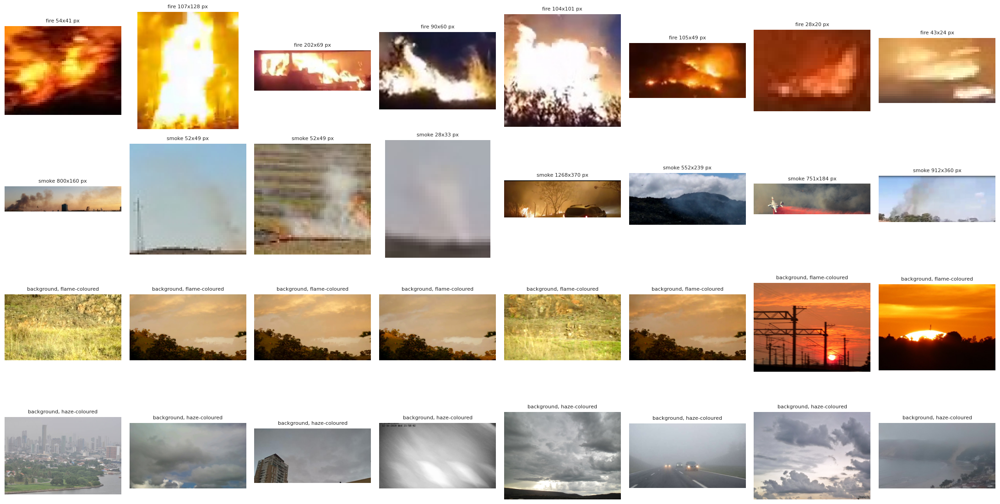

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/eda_crops_and_hard_negatives.png


In [34]:
crop_pool = train_boxes[(train_boxes["box_w_px"] >= MIN_CROP_PIXELS) & (train_boxes["box_h_px"] >= MIN_CROP_PIXELS)]
background_train = train_images[train_images["boxes"] == 0]
warm_negatives = background_train.sort_values("warm_share", ascending=False).head(8)
grey_negatives = background_train.sort_values("grey_share", ascending=False).head(8)

fig, axes = plt.subplots(4, 8, figsize=(22, 11.5))
for ax in axes.flatten():
    ax.axis("off")
for row_number, class_name in enumerate(CLASS_ORDER):
    class_rows = crop_pool[crop_pool["class"] == class_name]
    if len(class_rows) > 8:
        class_rows = class_rows.sample(8, random_state=SEED)
    for column_number, (_, box_row) in enumerate(class_rows.iterrows()):
        with Image.open(box_row["image"]) as image:
            crop = crop_box(image.convert("RGB"), box_row["xc"], box_row["yc"], box_row["w"], box_row["h"])
        ax = axes[row_number, column_number]
        ax.imshow(crop)
        ax.set_title(f"{class_name} {int(box_row['box_w_px'])}x{int(box_row['box_h_px'])} px", fontsize=8)
for row_number, (label, negatives) in enumerate([("flame-coloured", warm_negatives), ("haze-coloured", grey_negatives)]):
    for column_number, (_, image_row) in enumerate(negatives.iterrows()):
        ax = axes[row_number + 2, column_number]
        with Image.open(image_row["image"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(f"background, {label}", fontsize=8)
plt.tight_layout()
save_figure(fig, "eda_crops_and_hard_negatives")

### 6.11 File name prefixes

D-Fire file names start with a few letters before the number. They are not documented as separate sources, but they hint at how the images were collected (for example web images against video frames). The table shows how the prefixes spread over the splits and image types. If one prefix holds nearly all of one image type, the model may learn that collection's look rather than fire itself.

In [35]:
prefix_split = pd.crosstab(manifest["prefix"], manifest["split"])
prefix_split = prefix_split.reindex(columns=split_order, fill_value=0)
prefix_split["total"] = prefix_split.sum(axis=1)
prefix_split = prefix_split.sort_values("total", ascending=False).head(15)
save_table(prefix_split, "eda_prefix_per_split")

prefix_type = pd.crosstab(manifest["prefix"], manifest["image_type"], normalize="index") * 100
prefix_type = prefix_type.reindex(index=prefix_split.index, columns=IMAGE_TYPES, fill_value=0)
save_table(prefix_type.round(1), "eda_prefix_image_type_percent")

split,train,val,test,total
prefix,,,,
WEB,7189,1262,2340,10791
AoF,883,183,1328,2394
PublicDataset,645,93,273,1011


image_type,fire only,smoke only,fire and smoke,background
prefix,,,,
WEB,4.7,25.1,33.1,37.1
AoF,5.0,23.9,8.9,62.2
PublicDataset,8.9,62.5,12.2,16.4


### 6.12 Class imbalance in the training split

This table feeds section 8. When the ratio of majority to minority train boxes exceeds `IMBALANCE_RATIO_THRESHOLD`, augmented copies of minority-class images are added to the training list only.

In [36]:
gap_rows = []
train_box_totals_eda = {}
for class_name in CLASS_ORDER:
    total = int(train_images[class_name].sum())
    train_box_totals_eda[class_name] = total
    gap_rows.append({
        "class": class_name,
        "train boxes": total,
        "images containing it": int((train_images[class_name] > 0).sum()),
    })
gap_rows.append({
    "class": "background images",
    "train boxes": 0,
    "images containing it": int((train_images["boxes"] == 0).sum()),
})
imbalance_eda = pd.DataFrame(gap_rows).set_index("class")
majority_eda = int(imbalance_eda.loc[CLASS_ORDER, "train boxes"].max())
minority_eda = int(imbalance_eda.loc[CLASS_ORDER, "train boxes"].min())
ratio_eda = majority_eda / max(minority_eda, 1)
ratio_frame = pd.DataFrame([{
    "majority train boxes": majority_eda,
    "minority train boxes": minority_eda,
    "ratio": round(ratio_eda, 3),
    "will augment train (ratio > threshold)": ratio_eda > IMBALANCE_RATIO_THRESHOLD,
}]).set_index("majority train boxes")
save_table(imbalance_eda, "eda_train_class_counts")
save_table(ratio_frame, "eda_train_class_imbalance")

,train boxes,images containing it
class,,
fire,8360,3034
smoke,5776,5023
background images,0,3257


,minority train boxes,ratio,will augment train (ratio > threshold)
majority train boxes,,,
8360,5776,1.447,True


## 7. PCA on image-level features

PCA (principal component analysis) turns many correlated numbers into a few new axes, ordered by how much of the variation they explain. Each image becomes one row built from its class counts, box statistics, and brightness features. Plotting the first two components shows whether val and test cover the same kinds of images as training before any detector is trained.

### 7.1 Image-level PCA

Each feature is standardised (mean 0, standard deviation 1) first, so that large numbers such as image width do not dominate small ones such as `warm_share`. The loadings table shows which features drive the first two components.

In [37]:
IMAGE_FEATURES = CLASS_ORDER + [
    "boxes", "width", "height", "brightness", "contrast", "mean_r", "mean_g", "mean_b",
    "saturation", "warm_share", "grey_share", "mean_box_area", "mean_aspect", "mean_xc", "mean_yc",
]

pca_data = manifest.copy()
feature_matrix = pca_data[IMAGE_FEATURES].to_numpy(dtype=float)
scaled_features = StandardScaler().fit_transform(feature_matrix)

image_pca = PCA(n_components=5, random_state=SEED)
image_components = image_pca.fit_transform(scaled_features)
pca_data["PC1"] = image_components[:, 0]
pca_data["PC2"] = image_components[:, 1]

variance_rows = []
cumulative = 0.0
for index, ratio in enumerate(image_pca.explained_variance_ratio_):
    cumulative += ratio
    variance_rows.append({"component": f"PC{index + 1}", "explained variance %": ratio * 100, "cumulative %": cumulative * 100})
save_table(pd.DataFrame(variance_rows).set_index("component").round(1), "pca_image_explained_variance")

loadings = pd.DataFrame(image_pca.components_[:2].T, index=IMAGE_FEATURES, columns=["PC1", "PC2"])
loadings["abs PC1"] = loadings["PC1"].abs()
loadings = loadings.sort_values("abs PC1", ascending=False).drop(columns="abs PC1")
loadings.index.name = "feature"
save_table(loadings.round(3), "pca_image_loadings")

,explained variance %,cumulative %
component,,
PC1,28.9,28.9
PC2,16.9,45.8
PC3,11.4,57.2
PC4,8.8,66.0
PC5,6.8,72.8


,PC1,PC2
feature,,
mean_g,0.428,0.094
brightness,0.426,0.117
mean_b,0.412,0.048
mean_r,0.387,0.185
grey_share,0.299,0.032
saturation,-0.256,0.080
fire,-0.234,0.318
boxes,-0.212,0.416
contrast,0.195,0.009


Left: images coloured by image type. Right: the same points coloured by split. If val or test points sit where there are no training points, those images are unlike anything in training and will score lower. If background images overlap the fire and smoke clouds, the simple image statistics cannot tell them apart and the detector has to rely on local texture.

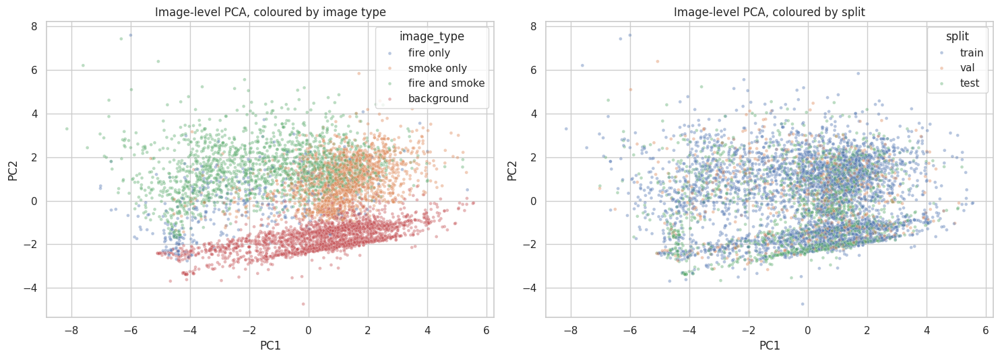

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/pca_image_level.png


In [38]:
plot_points = pca_data
if len(plot_points) > 6000:
    plot_points = pca_data.sample(6000, random_state=SEED)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=plot_points, x="PC1", y="PC2", hue="image_type", hue_order=IMAGE_TYPES, alpha=0.4, s=12, ax=axes[0])
axes[0].set_title("Image-level PCA, coloured by image type")
sns.scatterplot(data=plot_points, x="PC1", y="PC2", hue="split", hue_order=split_order, alpha=0.4, s=12, ax=axes[1])
axes[1].set_title("Image-level PCA, coloured by split")
plt.tight_layout()
save_figure(fig, "pca_image_level")

## 8. Build the training set

Every real image in the training split (after the 85/15 carve-out from published train) starts in the training list. Val and test stay fixed lists of real images only; they are never copied or augmented.

When majority train box count divided by minority train box count exceeds `IMBALANCE_RATIO_THRESHOLD`, augmented copies of training images that contain the minority class are appended. Transforms match common CCTV drift: horizontal flip, brightness and contrast, blur, JPEG compression, and downscale. Vertical flips are excluded because flames and smoke rise.

All experiments in section 10 use the same training list written here.

### 8.1 Real training images and class counts

Every cleaned image left in the training split after section 5 is listed here. Val and test are not included.

In [39]:
TRAIN_LISTS = {}
real_train_paths = []
for image_path in TRAIN_POOL_IMAGES:
    real_train_paths.append(Path(image_path))

train_box_counts = class_counts_for_images(real_train_paths)
count_rows = []
for class_name in CLASS_ORDER:
    count_rows.append({
        "class": class_name,
        "train boxes": int(train_box_counts.get(NAME_TO_ID[class_name], 0)),
    })
train_count_table = pd.DataFrame(count_rows).set_index("class")
save_table(train_count_table, "train_real_box_counts")

majority_boxes = int(train_count_table["train boxes"].max())
minority_boxes = int(train_count_table["train boxes"].min())
minority_class = train_count_table["train boxes"].idxmin()
if minority_boxes > 0:
    imbalance_ratio = majority_boxes / minority_boxes
else:
    imbalance_ratio = float("inf")

imbalance_table = pd.DataFrame([{
    "minority class": minority_class,
    "majority boxes": majority_boxes,
    "minority boxes": minority_boxes,
    "ratio": round(imbalance_ratio, 3),
    "augment train": imbalance_ratio > IMBALANCE_RATIO_THRESHOLD,
}]).set_index("minority class")
save_table(imbalance_table, "train_imbalance_decision")
display(imbalance_table)

,train boxes
class,
fire,8360
smoke,5776


,majority boxes,minority boxes,ratio,augment train
minority class,,,,
smoke,8360,5776,1.447,True


,majority boxes,minority boxes,ratio,augment train
minority class,,,,
smoke,8360,5776,1.447,True


### 8.2 Train-only augmentation when classes are imbalanced

Augmentation runs only when the table above marks `augment train` as True. Copies are made from real training images that contain the minority class, up to `MAX_AUG_COPIES_PER_IMAGE` per photo, until minority box count reaches majority or the copy limit stops progress.

Allowed transforms: horizontal flip, brightness and contrast, motion or Gaussian blur, downscale, and JPEG compression. No vertical flip.

In [40]:
def build_augmenter():
    bbox_params = A.BboxParams(format="yolo", label_fields=["class_labels"], min_visibility=0.3, clip=True)
    steps = [
        A.HorizontalFlip(p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.7),
        A.OneOf([
            A.MotionBlur(blur_limit=7),
            A.GaussianBlur(blur_limit=(3, 5)),
        ], p=0.4),
        A.Downscale(scale_range=(0.5, 0.9), p=0.3),
        A.ImageCompression(quality_range=(40, 90), p=0.3),
    ]
    return A.Compose(steps, bbox_params=bbox_params, seed=SEED)


augmenter = build_augmenter()
AUG_IMAGE_DIR = MERGED / "images" / "aug"
AUG_LABEL_DIR = MERGED / "labels" / "aug"
for folder in [AUG_IMAGE_DIR, AUG_LABEL_DIR]:
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True)


def make_augmented_copy(image_path, copy_name):
    rows = read_labels(label_path_for(image_path))
    boxes_in = []
    labels_in = []
    for row in rows:
        box = clean_box(row[1], row[2], row[3], row[4])
        if box is None:
            continue
        boxes_in.append(box)
        labels_in.append(row[0])
    image = np.array(Image.open(image_path).convert("RGB"))
    try:
        result = augmenter(image=image, bboxes=boxes_in, class_labels=labels_in)
    except ValueError as error:
        print("Skipped", Path(image_path).name, error)
        return None

    new_rows = []
    for class_id, box in zip(result["class_labels"], result["bboxes"]):
        new_rows.append([int(class_id), float(box[0]), float(box[1]), float(box[2]), float(box[3])])
    if not new_rows:
        return None

    target_image = AUG_IMAGE_DIR / f"{copy_name}.jpg"
    Image.fromarray(result["image"]).save(target_image, quality=95)
    write_labels(label_path_for(target_image), new_rows)
    return target_image


AUG_RECORDS = []
aug_paths = []
aug_box_counts = Counter(train_box_counts)
copies_per_image = Counter()

if imbalance_ratio > IMBALANCE_RATIO_THRESHOLD:
    minority_id = NAME_TO_ID[minority_class]
    candidates = train_images[train_images[minority_class] > 0].copy()
    candidates["share"] = candidates[minority_class] / candidates["boxes"]
    candidates = candidates.sort_values("share", ascending=False)

    for copy_round in range(MAX_AUG_COPIES_PER_IMAGE):
        if aug_box_counts[minority_id] >= majority_boxes:
            break
        for index, row in candidates.iterrows():
            if aug_box_counts[minority_id] >= majority_boxes:
                break
            if copies_per_image[index] >= MAX_AUG_COPIES_PER_IMAGE:
                continue
            copy_number = copies_per_image[index]
            copies_per_image[index] += 1
            copy_name = f"aug_{minority_class}_{copy_number}_{Path(row['image']).stem}"
            new_path = make_augmented_copy(row["image"], copy_name)
            if new_path is None:
                continue
            for new_row in read_labels(label_path_for(new_path)):
                aug_box_counts[int(new_row[0])] += 1
            aug_paths.append(new_path)
            AUG_RECORDS.append({"original": Path(row["image"]), "copy": new_path, "class": minority_class})

    after_rows = []
    for class_name in CLASS_ORDER:
        class_id = NAME_TO_ID[class_name]
        after_rows.append({
            "class": class_name,
            "boxes before aug": int(train_box_counts.get(class_id, 0)),
            "boxes after aug": int(aug_box_counts.get(class_id, 0)),
            "augmented copies added": len(aug_paths) if class_name == minority_class else 0,
        })
    save_table(pd.DataFrame(after_rows).set_index("class"), "train_augmentation_result")
else:
    display(pd.DataFrame([{"result": "Class counts are close enough; no stored augmented copies"}]))

final_train_paths = list(real_train_paths) + aug_paths
TRAIN_LISTS["train"] = write_list("train", final_train_paths)
print("Training images (real + augmented):", len(final_train_paths))

,boxes before aug,boxes after aug,augmented copies added
class,,,
fire,8360,8360,0
smoke,5776,8360,2309


Training images (real + augmented): 11026


### 8.3 Augmented copies next to their originals

When augmentation ran, each pair shows a real training image (top) and one augmented copy (bottom). Check that boxes still sit on fire and smoke.

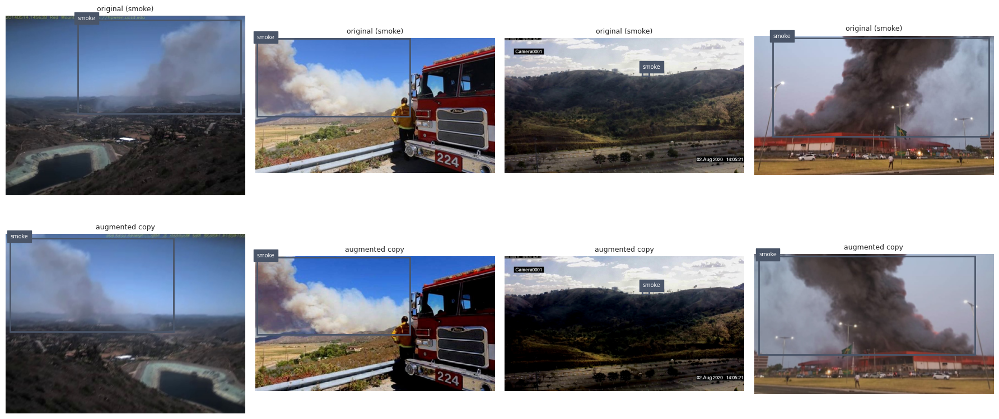

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/augmented_examples.png


In [41]:
preview_records = list(AUG_RECORDS)
random.Random(SEED).shuffle(preview_records)
preview_records = preview_records[:4]

if not preview_records:
    display(pd.DataFrame([{"result": "No augmented copies were added"}]))
else:
    fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
    for ax in axes.flatten():
        ax.axis("off")
    for column_number, record in enumerate(preview_records):
        draw_boxes(axes[0, column_number], record["original"], read_labels(label_path_for(record["original"])),
                   title=f"original ({record['class']})")
        draw_boxes(axes[1, column_number], record["copy"], read_labels(label_path_for(record["copy"])),
                   title="augmented copy")
    plt.tight_layout()
    save_figure(fig, "augmented_examples")

### 8.4 Compare training with val and test

Training may include augmented copies; val and test stay real-only and keep their natural class counts.

,train,val,test
class,,,
fire,8360,1507,2783
smoke,8360,1006,2153


,images,background images,background %
set,,,
train,11026,3257,29.5
val,1538,589,38.3
test,3941,1813,46.0


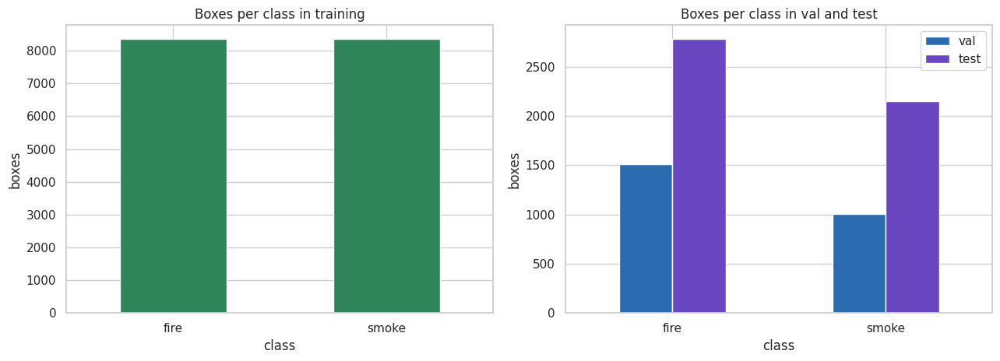

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/training_vs_eval_class_counts.png


In [42]:
split_counters = {
    "train": class_counts_for_images(read_list(TRAIN_LISTS["train"])),
    "val": class_counts_for_images(VAL_IMAGES),
    "test": class_counts_for_images(TEST_IMAGES),
}
all_classes_table = counts_table(split_counters)
save_table(all_classes_table, "training_vs_eval_class_counts")

image_rows = []
for set_name, image_paths in [
    ("train", read_list(TRAIN_LISTS["train"])),
    ("val", VAL_IMAGES),
    ("test", TEST_IMAGES),
]:
    empty = background_count(image_paths)
    image_rows.append({
        "set": set_name,
        "images": len(image_paths),
        "background images": empty,
        "background %": round(100 * empty / max(len(image_paths), 1), 1),
    })
image_table = pd.DataFrame(image_rows).set_index("set")
save_table(image_table, "training_vs_eval_images")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
all_classes_table[["train"]].plot(kind="bar", ax=axes[0], legend=False, color="#2f855a")
axes[0].set_title("Boxes per class in training")
axes[0].set_ylabel("boxes")
all_classes_table[["val", "test"]].plot(kind="bar", ax=axes[1], color=["#2b6cb0", "#6b46c1"])
axes[1].set_title("Boxes per class in val and test")
axes[1].set_ylabel("boxes")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
save_figure(fig, "training_vs_eval_class_counts")

### 8.5 Dataset file for Ultralytics

The YAML points at the training list, val list, and test list. Every experiment uses this same file.

In [43]:
def write_data_yaml(name, train_list, val_list, test_list):
    data = {
        "path": str(MERGED),
        "train": str(train_list),
        "val": str(val_list),
        "test": str(test_list),
        "names": CLASS_NAMES,
    }
    path = DATA_DIR / f"hazard_{name}.yaml"
    path.write_text(yaml.safe_dump(data, sort_keys=False))
    return path


DATA_YAMLS = {}
DATA_YAMLS["train"] = write_data_yaml("train", TRAIN_LISTS["train"], VAL_LIST, TEST_LIST)

yaml_rows = []
for name, path in DATA_YAMLS.items():
    yaml_rows.append({
        "training set": name,
        "train images": len(read_list(TRAIN_LISTS[name])),
        "val images": len(VAL_IMAGES),
        "test images": len(TEST_IMAGES),
        "yaml": str(path),
    })
save_table(pd.DataFrame(yaml_rows).set_index("training set"), "dataset_yaml_files")

,train images,val images,test images,yaml
training set,,,,
train,11026,1538,3941,/content/SAMS/datasets/vision/hazard/hazard_tr...


## 9. Training setup

### Transfer learning and fine-tuning

Every model starts from YOLOv8 weights pretrained on COCO. The pretrained network already knows edges, textures, and colours. Fine-tuning adapts it to fire and smoke.

YOLOv8 has three parts: the **backbone** (layers 0 to 9) turns the image into features, the **neck** mixes features at different scales, and the **head** predicts boxes and classes. Freezing a layer means its weights are not updated during training.

Two ways of fine-tuning are compared:

| Method | What happens |
|--------|--------------|
| single stage | All layers train from the first epoch |
| two stage | **Stage A:** the backbone is frozen (`freeze=10`) and only the neck and head train, for `STAGE_A_EPOCHS`. The new class layers settle without disturbing the pretrained features. **Stage B:** every layer is unfrozen and training continues from stage A's best weights with a 10 times lower learning rate and a cosine schedule, so the backbone is adjusted gently |

### Early stopping

After every epoch, Ultralytics scores the model on val. If the val fitness (0.1 times mAP50 plus 0.9 times mAP50-95) does not improve for `PATIENCE` epochs, training stops and the best epoch is kept. `MAX_EPOCHS` is only an upper limit.

### Hyperparameters

The optimizer is set to SGD on purpose. With the Ultralytics default `optimizer="auto"`, the learning rate below would be ignored and chosen automatically, which would make the experiments hard to compare.

In [44]:
BASE_HPARAMS = {
    "optimizer": "SGD",
    "lr0": 0.01,
    "lrf": 0.01,
    "momentum": 0.937,
    "weight_decay": 0.0005,
    "warmup_epochs": 3.0,
    "cos_lr": False,
    "box": 7.5,
    "cls": 0.5,
    "dfl": 1.5,
    "hsv_h": 0.010,
    "hsv_s": 0.6,
    "hsv_v": 0.4,
    "degrees": 0.0,
    "translate": 0.1,
    "scale": 0.5,
    "fliplr": 0.5,
    "flipud": 0.0,
    "mosaic": 1.0,
    "close_mosaic": 5,
}

HPARAM_MEANING = {
    "optimizer": "Update rule. SGD with momentum is the YOLOv8 reference setting",
    "lr0": "Starting learning rate",
    "lrf": "Final learning rate as a fraction of lr0",
    "momentum": "How much of the last update carries into the next one",
    "weight_decay": "Penalty on large weights, reduces overfitting",
    "warmup_epochs": "Epochs where the learning rate ramps up from a small value",
    "cos_lr": "Cosine learning-rate decay instead of linear",
    "box": "Weight of the box position loss",
    "cls": "Weight of the class loss",
    "dfl": "Weight of the distribution focal loss for box edges",
    "hsv_h": "Random hue change during training. Kept small, flame colour is a real cue",
    "hsv_s": "Random saturation change during training",
    "hsv_v": "Random brightness change during training",
    "degrees": "Random rotation during training. Kept at 0, the stored copies already rotate slightly",
    "translate": "Random shift during training",
    "scale": "Random zoom during training",
    "fliplr": "Chance of a left-right flip during training",
    "flipud": "Chance of an upside-down flip. 0, since flames and smoke always rise",
    "mosaic": "Chance of combining four images into one",
    "close_mosaic": "Turn mosaic off for the last N epochs so the model sees whole images",
}

hparam_rows = []
for name, value in BASE_HPARAMS.items():
    hparam_rows.append({"hyperparameter": name, "value": value, "meaning": HPARAM_MEANING[name]})
save_table(pd.DataFrame(hparam_rows).set_index("hyperparameter"), "hyperparameters_base")

,value,meaning
hyperparameter,,
optimizer,SGD,Update rule. SGD with momentum is the YOLOv8 r...
lr0,0.01,Starting learning rate
lrf,0.01,Final learning rate as a fraction of lr0
momentum,0.937,How much of the last update carries into the n...
weight_decay,0.0005,"Penalty on large weights, reduces overfitting"
warmup_epochs,3.0,Epochs where the learning rate ramps up from a...
cos_lr,False,Cosine learning-rate decay instead of linear
box,7.5,Weight of the box position loss
cls,0.5,Weight of the class loss


### Training and scoring functions

- `train_once` runs one Ultralytics training job.
- `score_model` scores saved weights on a split.
- `per_class_frame` turns Ultralytics metrics into a per-class DataFrame.
- `run_experiment` trains one experiment (single or two stage), reads the training log, scores the best weights on val, and records one row in `LEDGER`.

Reported val metrics:

| Metric | Meaning |
|--------|---------|
| precision | Share of predicted boxes that match a label |
| recall | Share of labelled boxes that are found |
| mAP50 | Mean average precision with a 50 percent box overlap needed |
| mAP50-95 | Mean of mAP from 50 to 95 percent overlap. The main score, because it also rewards tight boxes |
| fire recall, smoke recall | Recall of each class at the Ultralytics max-F1 point. Fire recall is the safety score, because a missed fire is the most costly error |

In [45]:
LEDGER = []
EXPERIMENTS = {}


def read_training_log(run_dir):
    results_csv = Path(run_dir) / "results.csv"
    if not results_csv.is_file():
        return pd.DataFrame()
    log = pd.read_csv(results_csv)
    clean_columns = []
    for column in log.columns:
        clean_columns.append(column.strip())
    log.columns = clean_columns
    return log


def train_once(run_name, data_yaml, weights, imgsz, epochs, freeze, hparams, seed):
    model = YOLO(weights)
    args = dict(hparams)
    args["data"] = str(data_yaml)
    args["epochs"] = epochs
    args["patience"] = PATIENCE
    args["imgsz"] = imgsz
    args["batch"] = BATCH
    args["device"] = YOLO_DEVICE
    args["project"] = str(MODELS_DIR)
    args["name"] = run_name
    args["exist_ok"] = True
    args["seed"] = seed
    args["deterministic"] = True
    args["cache"] = "ram"
    args["workers"] = 10
    args["plots"] = True
    args["freeze"] = freeze
    started = time.time()
    model.train(**args)
    elapsed = time.time() - started
    run_dir = Path(model.trainer.save_dir)
    best = run_dir / "weights" / "best.pt"
    del model
    free_memory()
    return run_dir, best, elapsed


def score_model(weights_path, data_yaml, imgsz, split="val", plots=False, name=None):
    model = YOLO(str(weights_path))
    kwargs = {
        "data": str(data_yaml),
        "split": split,
        "imgsz": imgsz,
        "batch": 16,
        "device": YOLO_DEVICE,
        "plots": plots,
        "verbose": False,
    }
    if name is not None:
        kwargs["project"] = str(RESULTS_DIR)
        kwargs["name"] = name
        kwargs["exist_ok"] = True
    metrics = model.val(**kwargs)
    del model
    free_memory()
    return metrics


def per_class_frame(metrics):
    box = metrics.box
    rows = []
    for position, class_id in enumerate(box.ap_class_index):
        rows.append({
            "class": metrics.names[int(class_id)],
            "precision": float(box.p[position]),
            "recall": float(box.r[position]),
            "mAP50": float(box.ap50[position]),
            "mAP50-95": float(box.ap[position]),
        })
    return pd.DataFrame(rows).set_index("class")


def class_value(per_class, class_name, column):
    if class_name not in per_class.index:
        return float("nan")
    return float(per_class.loc[class_name, column])


def best_epoch_of(log):
    if log.empty or "metrics/mAP50-95(B)" not in log.columns:
        return None
    fitness = 0.1 * log["metrics/mAP50(B)"] + 0.9 * log["metrics/mAP50-95(B)"]
    return int(log.loc[fitness.idxmax(), "epoch"])


def run_experiment(exp_id, change, data_name, weights="yolov8n.pt", imgsz=IMGSZ_BASE,
                   two_stage=False, hparams=None, seed=SEED, group="main"):
    if hparams is None:
        hparams = BASE_HPARAMS
    data_yaml = DATA_YAMLS[data_name]

    logs = []
    if two_stage:
        run_dir_a, best_a, time_a = train_once(
            f"{exp_id}_stageA_frozen", data_yaml, weights, imgsz,
            STAGE_A_EPOCHS, FREEZE_LAYERS, hparams, seed,
        )
        stage_b_hparams = dict(hparams)
        stage_b_hparams["lr0"] = hparams["lr0"] / 10
        stage_b_hparams["warmup_epochs"] = 1.0
        stage_b_hparams["cos_lr"] = True
        run_dir, best, time_b = train_once(
            f"{exp_id}_stageB_unfrozen", data_yaml, str(best_a), imgsz,
            MAX_EPOCHS, None, stage_b_hparams, seed,
        )
        elapsed = time_a + time_b
        log_a = read_training_log(run_dir_a)
        log_a["stage"] = "A frozen"
        logs.append(log_a)
        log_b = read_training_log(run_dir)
        log_b["stage"] = "B unfrozen"
        logs.append(log_b)
    else:
        run_dir, best, elapsed = train_once(exp_id, data_yaml, weights, imgsz, MAX_EPOCHS, None, hparams, seed)
        log = read_training_log(run_dir)
        log["stage"] = "single"
        logs.append(log)

    full_log = pd.concat(logs, ignore_index=True)
    full_log["epoch overall"] = np.arange(1, len(full_log) + 1)
    last_log = logs[-1]

    metrics = score_model(best, data_yaml, imgsz)
    per_class = per_class_frame(metrics)

    summary = {
        "experiment_id": exp_id,
        "group": group,
        "change": change,
        "data": data_name,
        "weights_in": weights,
        "train images": len(read_list(TRAIN_LISTS[data_name])),
        "imgsz": imgsz,
        "two_stage": two_stage,
        "optimizer": hparams["optimizer"],
        "lr0": hparams["lr0"],
        "seed": seed,
        "epochs_run": len(last_log),
        "best_epoch": best_epoch_of(last_log),
        "stopped_early": len(last_log) < MAX_EPOCHS,
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "map50": float(metrics.box.map50),
        "map50_95": float(metrics.box.map),
    }
    for class_name in CLASS_ORDER:
        summary[f"{class_name}_recall"] = class_value(per_class, class_name, "recall")
        summary[f"{class_name}_map50_95"] = class_value(per_class, class_name, "mAP50-95")
    summary["safety_recall"] = summary[f"{SAFETY_CLASS}_recall"]
    summary["minutes"] = round(elapsed / 60, 1)
    summary["best_pt"] = str(best)

    recipe = {
        "data_name": data_name,
        "weights": weights,
        "imgsz": imgsz,
        "two_stage": two_stage,
        "hparams": dict(hparams),
    }
    LEDGER.append(summary)
    EXPERIMENTS[exp_id] = {"summary": summary, "per_class": per_class, "log": full_log, "recipe": recipe}

    with (Path(run_dir) / "experiment_summary.json").open("w") as handle:
        json.dump(summary, handle, indent=2)

    shown = ["experiment_id", "change", "epochs_run", "best_epoch", "stopped_early",
             "precision", "recall", "map50", "map50_95", "fire_recall", "smoke_recall", "minutes"]
    display(pd.DataFrame([summary])[shown].set_index("experiment_id").round(3))
    return summary

## 10. Experiments

Each experiment changes one thing compared with the best recipe so far. All use the same training YAML from section 8, early stopping with `PATIENCE` 3, and the fixed val split.

| Id | Change | Question it answers |
|----|--------|---------------------|
| E1 | YOLOv8n, `IMGSZ_BASE` (640), SGD, single stage | Baseline |
| E2 | Same as E1 at `IMGSZ_LARGE` (960) | Does a larger input help small fires? |
| E3 | Two-stage fine-tuning (`freeze=10`, then lr0/10) at the better image size | Does freezing the backbone first help? |
| E4 | AdamW with lr0 0.001 vs SGD | Which optimizer wins on val? |
| E5 | YOLOv8s with the winning recipe | Does a larger model help enough to deploy? |

### E1. Baseline YOLOv8n at 640 pixels

In [46]:
run_experiment(
    "hazard_e1_baseline_640",
    "YOLOv8n, single-stage fine-tuning, 640 pixels",
    data_name="train",
    imgsz=IMGSZ_BASE,
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/hazard/hazard_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.6, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=hazard_e1_baseline_640, nbs=64, nms=No

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,fire_recall,smoke_recall,minutes
experiment_id,,,,,,,,,,,
hazard_e1_baseline_640,"YOLOv8n, single-stage fine-tuning, 640 pixels",4,1,True,0.428,0.441,0.376,0.175,0.345,0.537,4.2


{'experiment_id': 'hazard_e1_baseline_640',
 'group': 'main',
 'change': 'YOLOv8n, single-stage fine-tuning, 640 pixels',
 'data': 'train',
 'weights_in': 'yolov8n.pt',
 'train images': 11026,
 'imgsz': 640,
 'two_stage': False,
 'optimizer': 'SGD',
 'lr0': 0.01,
 'seed': 42,
 'epochs_run': 4,
 'best_epoch': 1,
 'stopped_early': True,
 'precision': 0.42770002613434643,
 'recall': 0.44091786375311504,
 'map50': 0.3763885828743123,
 'map50_95': 0.17545821807662393,
 'fire_recall': 0.34505640345056404,
 'fire_map50_95': 0.132927415902325,
 'smoke_recall': 0.536779324055666,
 'smoke_map50_95': 0.2179890202509228,
 'safety_recall': 0.34505640345056404,
 'minutes': 4.2,
 'best_pt': '/content/drive/MyDrive/SAMS/models/vision/hazard/hazard_e1_baseline_640/weights/best.pt'}

### E2. Same recipe at 960 pixels

Both 640 and 960 are always trained so the better image size is chosen on val, not assumed from the EDA alone.

In [47]:
run_experiment(
    "hazard_e2_imgsz_960",
    "YOLOv8n, single-stage fine-tuning, 960 pixels",
    data_name="train",
    imgsz=IMGSZ_LARGE,
)

score_640 = EXPERIMENTS["hazard_e1_baseline_640"]["summary"]["map50_95"]
score_960 = EXPERIMENTS["hazard_e2_imgsz_960"]["summary"]["map50_95"]
if score_960 > score_640:
    BEST_IMGSZ = IMGSZ_LARGE
    BEST_SINGLE_ID = "hazard_e2_imgsz_960"
else:
    BEST_IMGSZ = IMGSZ_BASE
    BEST_SINGLE_ID = "hazard_e1_baseline_640"

size_choice = pd.DataFrame([
    {"image size": IMGSZ_BASE, "experiment": "hazard_e1_baseline_640", "val mAP50-95": score_640},
    {"image size": IMGSZ_LARGE, "experiment": "hazard_e2_imgsz_960", "val mAP50-95": score_960},
]).set_index("image size")
save_table(size_choice.round(4), "choice_image_size")
print("Image size used from here on:", BEST_IMGSZ)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/hazard/hazard_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.6, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=hazard_e2_imgsz_960, nbs=64, nms=None,

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,fire_recall,smoke_recall,minutes
experiment_id,,,,,,,,,,,
hazard_e2_imgsz_960,"YOLOv8n, single-stage fine-tuning, 960 pixels",25,25,False,0.733,0.652,0.721,0.403,0.581,0.724,41.0


,experiment,val mAP50-95
image size,,
640,hazard_e1_baseline_640,0.1755
960,hazard_e2_imgsz_960,0.4035


Image size used from here on: 960


### E3. Two-stage fine-tuning at the chosen size

Stage A freezes the first `FREEZE_LAYERS` (backbone) layers. Stage B unfreezes all layers and continues at one tenth of `lr0` with a cosine schedule. Both stages use early stopping.

In [49]:
run_experiment(
    "hazard_e3_two_stage",
    f"Two-stage fine-tuning at {BEST_IMGSZ}px: freeze {FREEZE_LAYERS} layers, then lr0/10",
    data_name="train",
    imgsz=BEST_IMGSZ,
    two_stage=True,
)

single_score = EXPERIMENTS[BEST_SINGLE_ID]["summary"]["map50_95"]
two_stage_score = EXPERIMENTS["hazard_e3_two_stage"]["summary"]["map50_95"]
USE_TWO_STAGE = two_stage_score > single_score

stage_choice = pd.DataFrame([
    {"fine-tuning": "single stage", "experiment": BEST_SINGLE_ID, "val mAP50-95": single_score},
    {"fine-tuning": "two stage", "experiment": "hazard_e3_two_stage", "val mAP50-95": two_stage_score},
]).set_index("fine-tuning")
save_table(stage_choice.round(4), "choice_fine_tuning")

FINAL_RECIPE = {
    "data_name": "train",
    "imgsz": BEST_IMGSZ,
    "two_stage": USE_TWO_STAGE,
    "hparams": dict(BASE_HPARAMS),
}
if USE_TWO_STAGE:
    BEST_SO_FAR_ID = "hazard_e3_two_stage"
    BEST_SO_FAR_SCORE = two_stage_score
else:
    BEST_SO_FAR_ID = BEST_SINGLE_ID
    BEST_SO_FAR_SCORE = single_score
print("Two-stage fine-tuning used from here on:", USE_TWO_STAGE)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/hazard/hazard_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.01, hsv_s=0.6, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=hazard_e3_two_stage_stageA_frozen, nbs=6

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,fire_recall,smoke_recall,minutes
experiment_id,,,,,,,,,,,
hazard_e3_two_stage,Two-stage fine-tuning at 960px: freeze 10 laye...,21,18,True,0.693,0.644,0.693,0.372,0.573,0.714,46.5


,experiment,val mAP50-95
fine-tuning,,
single stage,hazard_e2_imgsz_960,0.4035
two stage,hazard_e3_two_stage,0.3724


Two-stage fine-tuning used from here on: False


### E4. AdamW lr0 0.001 vs SGD

Everything matches the recipe above except the optimizer. AdamW uses `lr0` 0.001 and `momentum` 0.9 (beta1). The winner is kept for E5.

In [50]:
ADAMW_HPARAMS = dict(FINAL_RECIPE["hparams"])
ADAMW_HPARAMS["optimizer"] = "AdamW"
ADAMW_HPARAMS["lr0"] = 0.001
ADAMW_HPARAMS["momentum"] = 0.9

run_experiment(
    "hazard_e4_adamw",
    "AdamW lr0 0.001 with the best fine-tuning choice so far",
    data_name="train",
    imgsz=FINAL_RECIPE["imgsz"],
    two_stage=FINAL_RECIPE["two_stage"],
    hparams=ADAMW_HPARAMS,
)

adamw_score = EXPERIMENTS["hazard_e4_adamw"]["summary"]["map50_95"]
sgd_score = BEST_SO_FAR_SCORE
optimizer_rows = []
for name in ["optimizer", "lr0", "momentum"]:
    optimizer_rows.append({
        "hyperparameter": name,
        "SGD recipe": FINAL_RECIPE["hparams"][name],
        "AdamW run": ADAMW_HPARAMS[name],
    })
optimizer_rows.append({"hyperparameter": "val mAP50-95", "SGD recipe": round(sgd_score, 4), "AdamW run": round(adamw_score, 4)})
save_table(pd.DataFrame(optimizer_rows).set_index("hyperparameter"), "choice_optimizer")

if adamw_score > sgd_score:
    FINAL_RECIPE["hparams"] = ADAMW_HPARAMS
    BEST_SO_FAR_SCORE = adamw_score
    BEST_SO_FAR_ID = "hazard_e4_adamw"
    print("AdamW is kept for E5.")
else:
    print("SGD is kept for E5.")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/hazard/hazard_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.6, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.9, mosaic=1.0, multi_scale=0.0, name=hazard_e4_adamw, nbs=64, nms=None, opse

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,fire_recall,smoke_recall,minutes
experiment_id,,,,,,,,,,,
hazard_e4_adamw,AdamW lr0 0.001 with the best fine-tuning choi...,25,25,False,0.705,0.666,0.715,0.404,0.596,0.736,40.6


,SGD recipe,AdamW run
hyperparameter,,
optimizer,SGD,AdamW
lr0,0.01,0.001
momentum,0.937,0.9
val mAP50-95,0.4035,0.4038


AdamW is kept for E5.


### E5. YOLOv8s with the winning recipe

In [51]:
run_experiment(
    "hazard_e5_yolov8s",
    "YOLOv8s with the best image size, fine-tuning, and optimizer so far",
    data_name="train",
    weights="yolov8s.pt",
    imgsz=FINAL_RECIPE["imgsz"],
    two_stage=FINAL_RECIPE["two_stage"],
    hparams=FINAL_RECIPE["hparams"],
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/hazard/hazard_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.6, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.9, mosaic=1.0, multi_scale=0.0, name=hazard_e5_yolov8s, nbs=64, nms=None, op

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,fire_recall,smoke_recall,minutes
experiment_id,,,,,,,,,,,
hazard_e5_yolov8s,"YOLOv8s with the best image size, fine-tuning,...",25,25,False,0.73,0.676,0.721,0.413,0.607,0.746,75.1


{'experiment_id': 'hazard_e5_yolov8s',
 'group': 'main',
 'change': 'YOLOv8s with the best image size, fine-tuning, and optimizer so far',
 'data': 'train',
 'weights_in': 'yolov8s.pt',
 'train images': 11026,
 'imgsz': 960,
 'two_stage': False,
 'optimizer': 'AdamW',
 'lr0': 0.001,
 'seed': 42,
 'epochs_run': 25,
 'best_epoch': 25,
 'stopped_early': False,
 'precision': 0.7301565166161332,
 'recall': 0.6763366231379688,
 'map50': 0.721386200063977,
 'map50_95': 0.41300279020563446,
 'fire_recall': 0.6071665560716656,
 'fire_map50_95': 0.32955609793675034,
 'smoke_recall': 0.745506690204272,
 'smoke_map50_95': 0.49644948247451837,
 'safety_recall': 0.6071665560716656,
 'minutes': 75.1,
 'best_pt': '/content/drive/MyDrive/SAMS/models/vision/hazard/hazard_e5_yolov8s/weights/best.pt'}

## 11. Compare the experiments and choose the model

### 11.1 Experiment ledger

One row per training run, with everything that was changed and every val score. The left chart compares the overall val scores, the right chart the recall of each class.

,group,change,data,weights_in,train images,imgsz,two_stage,optimizer,lr0,seed,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,fire_recall,smoke_recall,fire_map50_95,smoke_map50_95,minutes
experiment_id,,,,,,,,,,,,,,,,,,,,,,
hazard_e1_baseline_640,main,"YOLOv8n, single-stage fine-tuning, 640 pixels",train,yolov8n.pt,11026,640,False,SGD,0.010,42,4,1,True,0.4277,0.4409,0.3764,0.1755,0.3451,0.5368,0.1329,0.2180,4.2
hazard_e2_imgsz_960,main,"YOLOv8n, single-stage fine-tuning, 960 pixels",train,yolov8n.pt,11026,960,False,SGD,0.010,42,25,25,False,0.7326,0.6521,0.7206,0.4035,0.5806,0.7237,0.3240,0.4830,41.0
hazard_e3_two_stage,main,Two-stage fine-tuning at 960px: freeze 10 laye...,train,yolov8n.pt,11026,960,True,SGD,0.010,42,21,18,True,0.6931,0.6438,0.6933,0.3724,0.5733,0.7142,0.3124,0.4323,46.5
hazard_e4_adamw,main,AdamW lr0 0.001 with the best fine-tuning choi...,train,yolov8n.pt,11026,960,False,AdamW,0.001,42,25,25,False,0.7047,0.6657,0.7147,0.4038,0.5958,0.7356,0.3149,0.4928,40.6
hazard_e5_yolov8s,main,"YOLOv8s with the best image size, fine-tuning,...",train,yolov8s.pt,11026,960,False,AdamW,0.001,42,25,25,False,0.7302,0.6763,0.7214,0.4130,0.6072,0.7455,0.3296,0.4964,75.1


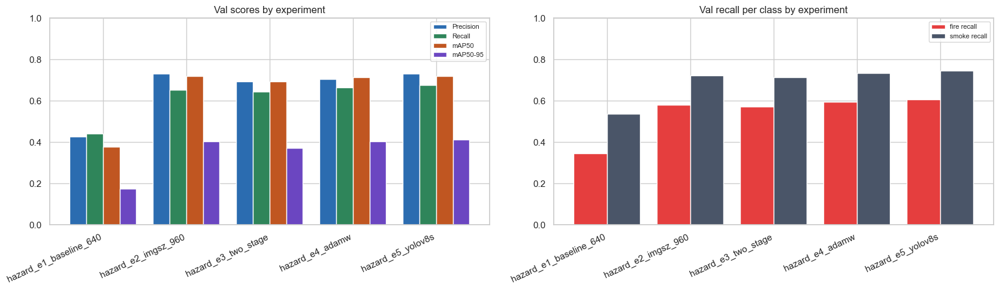

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/experiment_comparison.png


In [52]:
ledger_frame = pd.DataFrame(LEDGER)
ledger_columns = ["experiment_id", "group", "change", "data", "weights_in", "train images", "imgsz", "two_stage",
                  "optimizer", "lr0", "seed", "epochs_run", "best_epoch", "stopped_early", "precision", "recall",
                  "map50", "map50_95", "fire_recall", "smoke_recall", "fire_map50_95", "smoke_map50_95", "minutes"]
ledger_view = ledger_frame[ledger_columns].set_index("experiment_id").round(4)
save_table(ledger_view, "experiment_ledger")

main_ledger = ledger_frame[ledger_frame["group"] == "main"].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
positions = np.arange(len(main_ledger))
bar_width = 0.2
series = [
    ("precision", "Precision", "#2b6cb0"),
    ("recall", "Recall", "#2f855a"),
    ("map50", "mAP50", "#c05621"),
    ("map50_95", "mAP50-95", "#6b46c1"),
]
for offset, (column, label, color) in enumerate(series):
    axes[0].bar(positions + (offset - 1.5) * bar_width, main_ledger[column], bar_width, label=label, color=color)
axes[0].set_xticks(positions)
axes[0].set_xticklabels(main_ledger["experiment_id"], rotation=25, ha="right")
axes[0].set_ylim(0, 1)
axes[0].set_title("Val scores by experiment")
axes[0].legend(fontsize=8)

axes[1].bar(positions - 0.2, main_ledger["fire_recall"], 0.4, label="fire recall", color="#e53e3e")
axes[1].bar(positions + 0.2, main_ledger["smoke_recall"], 0.4, label="smoke recall", color="#4a5568")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(main_ledger["experiment_id"], rotation=25, ha="right")
axes[1].set_ylim(0, 1)
axes[1].set_title("Val recall per class by experiment")
axes[1].legend(fontsize=8)
plt.tight_layout()
save_figure(fig, "experiment_comparison")

### 11.2 Training curves

Each line is the val mAP50-95 after every epoch, and the val box loss next to it. A line that flattens long before it ends shows where early stopping stepped in. For two-stage runs, stage A and stage B are joined, so the jump where the backbone is unfrozen is visible. A val box loss that rises while mAP still climbs is an early sign of overfitting.

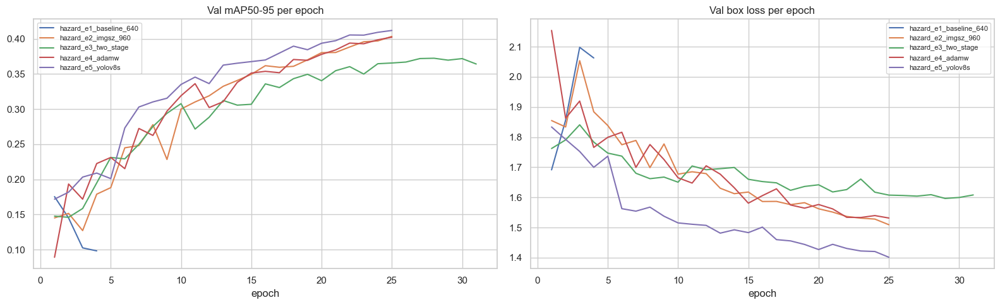

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/training_curves.png


In [53]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for exp_id, experiment in EXPERIMENTS.items():
    if experiment["summary"]["group"] != "main":
        continue
    log = experiment["log"]
    if "metrics/mAP50-95(B)" in log.columns:
        axes[0].plot(log["epoch overall"], log["metrics/mAP50-95(B)"], label=exp_id)
    if "val/box_loss" in log.columns:
        axes[1].plot(log["epoch overall"], log["val/box_loss"], label=exp_id)
axes[0].set_title("Val mAP50-95 per epoch")
axes[0].set_xlabel("epoch")
axes[1].set_title("Val box loss per epoch")
axes[1].set_xlabel("epoch")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
save_figure(fig, "training_curves")

### 11.3 Choose the winner

The winner is the main experiment with the highest val mAP50-95. If another experiment is within `CLOSE_SCORE_GAP` of it, the one with the higher fire recall wins instead, because a gap that small is within run-to-run noise and a missed fire matters most for SAMS.

In [54]:
ranked = main_ledger.sort_values("map50_95", ascending=False).reset_index(drop=True)
top_score = ranked.loc[0, "map50_95"]
close_runs = ranked[ranked["map50_95"] >= top_score - CLOSE_SCORE_GAP]
winner_row = close_runs.sort_values("safety_recall", ascending=False).iloc[0]

WINNER_ID = winner_row["experiment_id"]
WINNER = EXPERIMENTS[WINNER_ID]
BEST_WEIGHTS = Path(WINNER["summary"]["best_pt"])
BEST_IMGSZ_FINAL = int(WINNER["recipe"]["imgsz"])
BEST_DATA_YAML = DATA_YAMLS[WINNER["recipe"]["data_name"]]

save_table(pd.DataFrame([{
    "chosen experiment": WINNER_ID,
    "val mAP50-95": winner_row["map50_95"],
    "val mAP50": winner_row["map50"],
    "val fire recall": winner_row["fire_recall"],
    "val smoke recall": winner_row["smoke_recall"],
    "training set": WINNER["recipe"]["data_name"],
    "image size": BEST_IMGSZ_FINAL,
    "two stage": WINNER["recipe"]["two_stage"],
    "optimizer": WINNER["recipe"]["hparams"]["optimizer"],
    "weights": str(BEST_WEIGHTS),
}]).set_index("chosen experiment").round(4), "chosen_experiment")

,val mAP50-95,val mAP50,val fire recall,val smoke recall,training set,image size,two stage,optimizer,weights
chosen experiment,,,,,,,,,
hazard_e5_yolov8s,0.413,0.7214,0.6072,0.7455,train,960,False,AdamW,/content/drive/MyDrive/SAMS/models/vision/haza...


## 12. Evaluate the chosen model in detail

Everything in this section uses val only. Test is still untouched.

### 12.1 Per-class scores

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1944.0±1344.2 MB/s, size: 60.5 KB)
val: Scanning /content/SAMS/datasets/vision/hazard/merged/labels/pool.cache... 1538 images, 589 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1538/1538 430.1Mit/s 0.0s
val: /content/SAMS/datasets/vision/hazard/merged/images/pool/dfire_WEB07199.jpg: corrupt JPEG restored and saved
val: /content/SAMS/datasets/vision/hazard/merged/images/pool/dfire_WEB07305.jpg: corrupt JPEG restored and saved
val: /content/SAMS/datasets/vision/hazard/merged/images/pool/dfire_WEB07535.jpg: corrupt JPEG restored and saved
val: /content/SAMS/datasets/vision/hazard/merged/images/pool/dfire_WEB07539.jpg: corrupt JPEG restored and saved
val: /content/SAMS/datasets/vision/hazard/merged/images/pool/dfire_WEB07556.jpg: corrupt JPEG restored and saved
val: /content/SAMS/

,val boxes,precision,recall,mAP50,mAP50-95
class,,,,,
fire,1507,0.677,0.607,0.650,0.330
smoke,1006,0.784,0.746,0.793,0.496


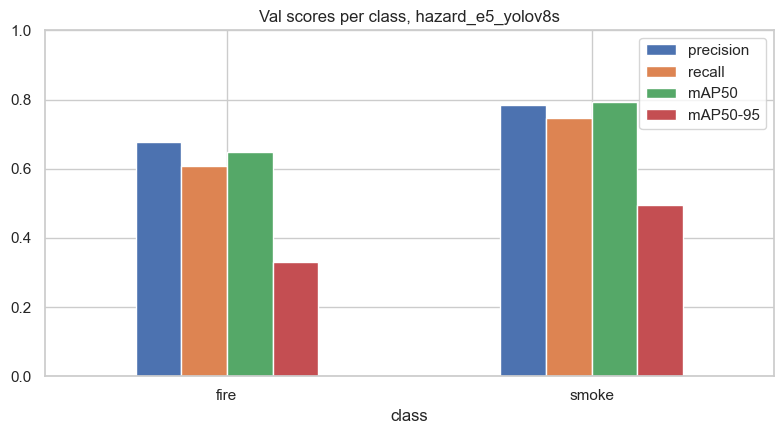

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/best_val_per_class.png


In [56]:
val_metrics = score_model(BEST_WEIGHTS, BEST_DATA_YAML, BEST_IMGSZ_FINAL, plots=True, name="hazard_best_val")
best_per_class = per_class_frame(val_metrics)

val_box_counts = class_counts_for_images(VAL_IMAGES)
count_column = []
for class_name in best_per_class.index:
    count_column.append(int(val_box_counts.get(NAME_TO_ID[class_name], 0)))
best_per_class.insert(0, "val boxes", count_column)
best_per_class = best_per_class.reindex(CLASS_ORDER)
save_table(best_per_class.round(3), "best_val_per_class")

fig, ax = plt.subplots(figsize=(8, 4.5))
best_per_class[["precision", "recall", "mAP50", "mAP50-95"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1)
ax.set_title(f"Val scores per class, {WINNER_ID}")
plt.xticks(rotation=0)
plt.tight_layout()
save_figure(fig, "best_val_per_class")

### 12.2 Confusion matrix

Columns are the true class, rows are the predicted class, and each column adds up to 1. The `background` row is labels the model missed, and the `background` column is predictions where there was no label.

The table under it pulls out the errors that matter most for SAMS: fire read as smoke (the alarm still fires, but as the wrong kind), fire not found at all (a missed fire), and boxes predicted where there was nothing (false alarms).

true,smoke,fire,background
predicted,,,
smoke,644,164,12980
fire,326,1298,27960
background,36,45,0


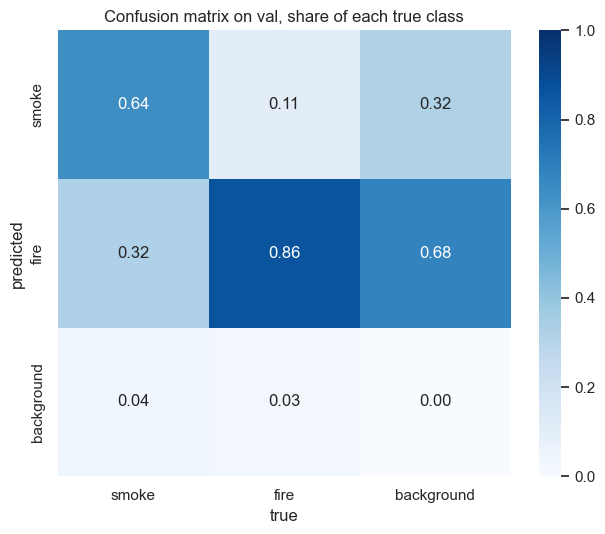

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/best_val_confusion_matrix.png


,true boxes,read as the other hazard,not found,predicted boxes with no label
class,,,,
fire,1507,0.109,0.030,27960
smoke,1006,0.324,0.036,12980


In [57]:
matrix = val_metrics.confusion_matrix.matrix
matrix_labels = []
for class_id in range(NUM_CLASSES):
    matrix_labels.append(CLASS_NAMES[class_id])
matrix_labels.append("background")
confusion = pd.DataFrame(matrix, index=matrix_labels, columns=matrix_labels)
confusion.index.name = "predicted"
confusion.columns.name = "true"
column_totals = confusion.sum(axis=0).replace(0, np.nan)
confusion_share = confusion / column_totals
save_table(confusion.astype(int), "best_val_confusion_counts")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(confusion_share, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Confusion matrix on val, share of each true class")
plt.tight_layout()
save_figure(fig, "best_val_confusion_matrix")

error_rows = []
for class_name in CLASS_ORDER:
    true_total = confusion[class_name].sum()
    read_as_other = 0.0
    for other_name in CLASS_ORDER:
        if other_name != class_name:
            read_as_other += confusion.loc[other_name, class_name]
    row = {"class": class_name, "true boxes": int(true_total)}
    if true_total > 0:
        row["read as the other hazard"] = read_as_other / true_total
        row["not found"] = confusion.loc["background", class_name] / true_total
    row["predicted boxes with no label"] = int(confusion.loc[class_name, "background"])
    error_rows.append(row)
save_table(pd.DataFrame(error_rows).set_index("class").round(3), "best_val_key_errors")

### 12.3 Precision-recall and F1 curves

Ultralytics records, for every class, precision, recall, and F1 at 1,000 confidence thresholds between 0 and 1. F1 is the balance of precision and recall. These curves are used in 12.4 to choose a threshold per class. The dashed line on the recall chart is `MIN_RECALL_SAFETY`.

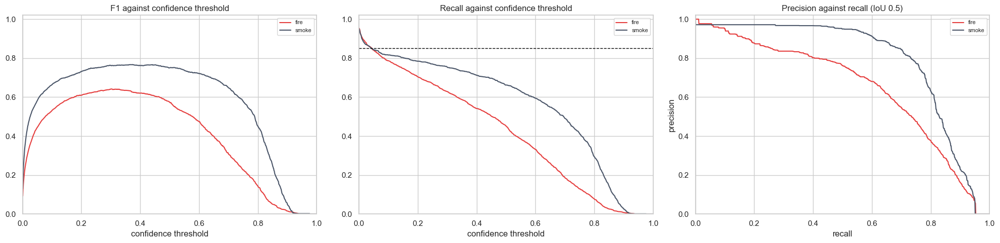

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/best_val_curves.png


In [58]:
box_metrics = val_metrics.box
THRESHOLD_GRID = np.asarray(box_metrics.px)
curve_rows = {}
for position, class_id in enumerate(box_metrics.ap_class_index):
    curve_rows[CLASS_NAMES[int(class_id)]] = position

curve_colors = {"fire": "#e53e3e", "smoke": "#4a5568"}
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for class_name in CLASS_ORDER:
    if class_name not in curve_rows:
        continue
    position = curve_rows[class_name]
    color = curve_colors[class_name]
    axes[0].plot(THRESHOLD_GRID, box_metrics.f1_curve[position], label=class_name, color=color)
    axes[1].plot(THRESHOLD_GRID, box_metrics.r_curve[position], label=class_name, color=color)
    if len(box_metrics.prec_values) > position:
        recall_axis = np.linspace(0, 1, len(box_metrics.prec_values[position]))
        axes[2].plot(recall_axis, box_metrics.prec_values[position], label=class_name, color=color)
axes[0].set_title("F1 against confidence threshold")
axes[0].set_xlabel("confidence threshold")
axes[1].set_title("Recall against confidence threshold")
axes[1].set_xlabel("confidence threshold")
axes[1].axhline(MIN_RECALL_SAFETY, color="black", linestyle="--", linewidth=1)
axes[2].set_title("Precision against recall (IoU 0.5)")
axes[2].set_xlabel("recall")
axes[2].set_ylabel("precision")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=8)
plt.tight_layout()
save_figure(fig, "best_val_curves")

### 12.4 One confidence threshold per class

A single threshold for both classes is a poor fit: fire and smoke reach different confidences, and missing a fire costs more than a false smoke box.

- The safety class (`SAFETY_CLASS`, fire) uses the highest threshold that still reaches `MIN_RECALL_SAFETY` recall. If that recall cannot be reached, the highest-F1 threshold is used and the table says so.
- The other class uses the threshold with the highest F1.
- Every threshold is kept between `THRESHOLD_MIN` and `THRESHOLD_MAX`.

The thresholds are written to `metadata.json` as `class_conf`. The live service reads only `conf` and passes it to `predict` for both classes, so `conf` is set to the lower of the two thresholds. That keeps the fire recall target in the live service today, at the cost of a lower smoke threshold than chosen here, until the service applies `class_conf` per class.

In [59]:
CLASS_CONF = {}
threshold_rows = []
for class_name in CLASS_ORDER:
    if class_name not in curve_rows:
        continue
    position = curve_rows[class_name]
    f1_values = np.asarray(box_metrics.f1_curve[position])
    recall_values = np.asarray(box_metrics.r_curve[position])
    precision_values = np.asarray(box_metrics.p_curve[position])
    chosen_index = int(np.argmax(f1_values))
    rule = "highest F1"
    if class_name == SAFETY_CLASS:
        meets_recall = np.where(recall_values >= MIN_RECALL_SAFETY)[0]
        if len(meets_recall) > 0:
            chosen_index = int(meets_recall.max())
            rule = f"highest threshold with recall >= {MIN_RECALL_SAFETY}"
        else:
            rule = "highest F1 (recall target not reachable)"
    threshold = float(np.clip(THRESHOLD_GRID[chosen_index], THRESHOLD_MIN, THRESHOLD_MAX))
    CLASS_CONF[class_name] = round(threshold, 3)
    threshold_rows.append({
        "class": class_name,
        "threshold": round(threshold, 3),
        "rule": rule,
        "precision at threshold": float(precision_values[chosen_index]),
        "recall at threshold": float(recall_values[chosen_index]),
        "F1 at threshold": float(f1_values[chosen_index]),
    })

GLOBAL_CONF = round(float(min(CLASS_CONF.values())), 3)
save_table(pd.DataFrame(threshold_rows).set_index("class").round(3), "best_val_class_thresholds")
print("Single threshold for the live service (lowest class threshold):", GLOBAL_CONF)

,threshold,rule,precision at threshold,recall at threshold,F1 at threshold
class,,,,,
fire,0.050,highest threshold with recall >= 0.85,0.285,0.853,0.427
smoke,0.374,highest F1,0.810,0.729,0.767


Single threshold for the live service (lowest class threshold): 0.05


### 12.5 Box-by-box analysis on val

The chosen model predicts every val image at a low confidence (`ANALYSIS_CONF`). Each prediction is matched to the label of the same class that it overlaps most, as long as the overlap (IoU, intersection over union) is at least `MATCH_IOU`. Each label can be matched once. Predictions are then kept or dropped with the per-class thresholds from 12.4.

From these matches, five analyses are built:

1. Recall by box size, to see whether small fires are the problem.
2. Bootstrap confidence intervals for precision, recall, and F1 at the per-class thresholds.
3. Confidence calibration: whether a confidence of 0.7 really means right about 70 percent of the time.
4. Frame-level alarms, which is what the live service actually reports.
5. Galleries of the worst misses and the worst false alarms.

In [60]:
def box_iou(box_a, box_b):
    """IoU of two [xc, yc, w, h] boxes in normalised coordinates."""
    a_left = box_a[0] - box_a[2] / 2
    a_right = box_a[0] + box_a[2] / 2
    a_top = box_a[1] - box_a[3] / 2
    a_bottom = box_a[1] + box_a[3] / 2
    b_left = box_b[0] - box_b[2] / 2
    b_right = box_b[0] + box_b[2] / 2
    b_top = box_b[1] - box_b[3] / 2
    b_bottom = box_b[1] + box_b[3] / 2
    overlap_w = max(0.0, min(a_right, b_right) - max(a_left, b_left))
    overlap_h = max(0.0, min(a_bottom, b_bottom) - max(a_top, b_top))
    overlap = overlap_w * overlap_h
    union = box_a[2] * box_a[3] + box_b[2] * box_b[3] - overlap
    if union <= 0:
        return 0.0
    return overlap / union


def confidence_of(prediction):
    return prediction[1]


def match_predictions(label_rows, prediction_rows):
    """Greedy matching, highest confidence first.

    label_rows: [class_id, xc, yc, w, h]
    prediction_rows: [class_id, confidence, xc, yc, w, h]
    Returns which labels were found, and (prediction, is_correct) pairs.
    """
    label_found = [False] * len(label_rows)
    outcomes = []
    for prediction in sorted(prediction_rows, key=confidence_of, reverse=True):
        best_overlap = 0.0
        best_label = -1
        for label_number, label in enumerate(label_rows):
            if label_found[label_number] or label[0] != prediction[0]:
                continue
            overlap = box_iou(prediction[2:6], label[1:5])
            if overlap > best_overlap:
                best_overlap = overlap
                best_label = label_number
        is_correct = best_overlap >= MATCH_IOU
        if is_correct:
            label_found[best_label] = True
        outcomes.append((prediction, is_correct))
    return label_found, outcomes


def predict_rows(model, image_paths, conf, imgsz):
    """Predictions per image as rows of [class_id, confidence, xc, yc, w, h]."""
    predictions = {}
    for start in range(0, len(image_paths), 32):
        chunk = image_paths[start:start + 32]
        chunk_paths = []
        for image_path in chunk:
            chunk_paths.append(str(image_path))
        results = model.predict(chunk_paths, conf=conf, imgsz=imgsz, device=YOLO_DEVICE, verbose=False)
        for image_path, result in zip(chunk, results):
            classes = result.boxes.cls.cpu().numpy()
            confidences = result.boxes.conf.cpu().numpy()
            positions = result.boxes.xywhn.cpu().numpy()
            rows = []
            for number in range(len(classes)):
                rows.append([
                    int(classes[number]), float(confidences[number]),
                    float(positions[number][0]), float(positions[number][1]),
                    float(positions[number][2]), float(positions[number][3]),
                ])
            predictions[str(image_path)] = rows
    return predictions


analysis_model = YOLO(str(BEST_WEIGHTS))
ALL_PREDICTIONS = predict_rows(analysis_model, VAL_IMAGES, ANALYSIS_CONF, BEST_IMGSZ_FINAL)
del analysis_model
free_memory()

image_sizes = {}
for image_path, width, height in zip(manifest["image"], manifest["width"], manifest["height"]):
    image_sizes[image_path] = (width, height)

true_positive = np.zeros((len(VAL_IMAGES), NUM_CLASSES))
false_positive = np.zeros((len(VAL_IMAGES), NUM_CLASSES))
false_negative = np.zeros((len(VAL_IMAGES), NUM_CLASSES))
label_records = []
calibration_records = []
KEPT_PREDICTIONS = {}
VAL_LABELS = {}

for image_number, image_path in enumerate(VAL_IMAGES):
    key = str(image_path)
    label_rows = read_labels(label_path_for(image_path))
    VAL_LABELS[key] = label_rows
    all_predictions = ALL_PREDICTIONS[key]

    kept = []
    for prediction in all_predictions:
        if prediction[1] >= CLASS_CONF.get(CLASS_NAMES[prediction[0]], GLOBAL_CONF):
            kept.append(prediction)
    KEPT_PREDICTIONS[key] = kept

    label_found, outcomes = match_predictions(label_rows, kept)
    width, height = image_sizes[key]
    for label, found in zip(label_rows, label_found):
        if found:
            true_positive[image_number, label[0]] += 1
        else:
            false_negative[image_number, label[0]] += 1
        label_records.append({
            "image": key,
            "class": CLASS_NAMES[label[0]],
            "size": size_bucket(label[3], label[4], width, height, BEST_IMGSZ_FINAL),
            "found": found,
        })
    for prediction, is_correct in outcomes:
        if not is_correct:
            false_positive[image_number, prediction[0]] += 1

    all_found, all_outcomes = match_predictions(label_rows, all_predictions)
    for prediction, is_correct in all_outcomes:
        calibration_records.append({
            "class": CLASS_NAMES[prediction[0]],
            "confidence": prediction[1],
            "correct": is_correct,
        })

label_results = pd.DataFrame(label_records)
calibration_results = pd.DataFrame(calibration_records)
print("Val labels checked:", len(label_results))
print("Val predictions checked for calibration:", len(calibration_results))

Val labels checked: 2513
Val predictions checked for calibration: 6400


#### Recall by box size

Each cell is the share of labels of that class and size that the model found at its per-class threshold. Sizes are measured at the chosen model's image size. Low recall only in the `small` column means more pixels (a larger image size, or tiling the frame) would help more than more data.

,small,medium,large,small labels,medium labels,large labels
class,,,,,,
fire,0.775,0.869,0.872,404,641,462
smoke,0.294,0.364,0.773,17,99,890


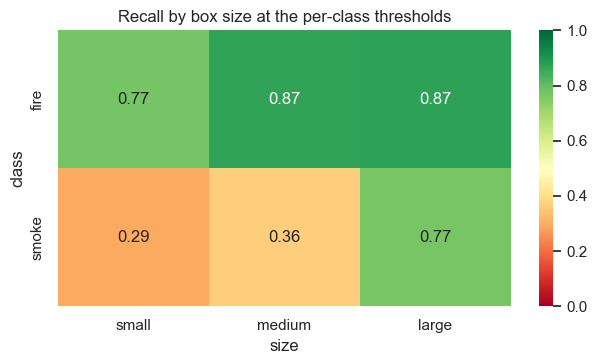

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/best_val_recall_by_size.png


In [61]:
size_recall = label_results.pivot_table(index="class", columns="size", values="found", aggfunc="mean")
size_recall = size_recall.reindex(index=CLASS_ORDER, columns=size_order)
size_count = label_results.pivot_table(index="class", columns="size", values="found", aggfunc="count")
size_count = size_count.reindex(index=CLASS_ORDER, columns=size_order).fillna(0).astype(int)
size_count.columns = ["small labels", "medium labels", "large labels"]
save_table(pd.concat([size_recall.round(3), size_count], axis=1), "best_val_recall_by_size")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.heatmap(size_recall.astype(float), annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax)
ax.set_title("Recall by box size at the per-class thresholds")
plt.tight_layout()
save_figure(fig, "best_val_recall_by_size")

#### Bootstrap confidence intervals

The val images are resampled with replacement `BOOTSTRAP_ROUNDS` times, and precision, recall, and F1 are recomputed each time. The 2.5 and 97.5 percentiles give a 95 percent interval. If two models have overlapping intervals, the difference between them is not reliable. Resampling whole images (not boxes) keeps the boxes of one image together, which is the honest choice when one image holds several fire boxes.

,threshold,precision,precision 2.5%,precision 97.5%,recall,recall 2.5%,recall 97.5%,F1 2.5%,F1 97.5%
class,,,,,,,,,
fire,0.050,0.290,0.273,0.308,0.845,0.818,0.867,0.410,0.453
smoke,0.374,0.802,0.776,0.828,0.725,0.694,0.755,0.737,0.787


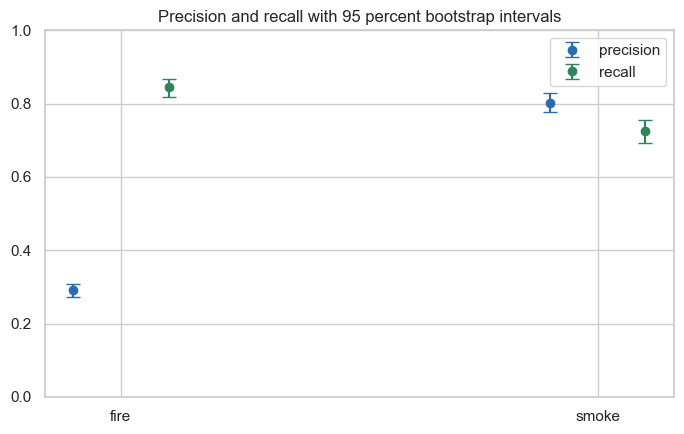

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/best_val_bootstrap_intervals.png


In [62]:
bootstrap_rng = np.random.default_rng(SEED)
image_count = len(VAL_IMAGES)
bootstrap_precision = []
bootstrap_recall = []
for _ in range(BOOTSTRAP_ROUNDS):
    sample = bootstrap_rng.integers(0, image_count, image_count)
    tp_sum = true_positive[sample].sum(axis=0)
    fp_sum = false_positive[sample].sum(axis=0)
    fn_sum = false_negative[sample].sum(axis=0)
    with np.errstate(divide="ignore", invalid="ignore"):
        bootstrap_precision.append(tp_sum / (tp_sum + fp_sum))
        bootstrap_recall.append(tp_sum / (tp_sum + fn_sum))
bootstrap_precision = np.array(bootstrap_precision)
bootstrap_recall = np.array(bootstrap_recall)
with np.errstate(divide="ignore", invalid="ignore"):
    bootstrap_f1 = 2 * bootstrap_precision * bootstrap_recall / (bootstrap_precision + bootstrap_recall)

tp_total = true_positive.sum(axis=0)
fp_total = false_positive.sum(axis=0)
fn_total = false_negative.sum(axis=0)
interval_rows = []
for class_name in CLASS_ORDER:
    class_id = NAME_TO_ID[class_name]
    if tp_total[class_id] + fn_total[class_id] == 0:
        continue
    precision = tp_total[class_id] / max(tp_total[class_id] + fp_total[class_id], 1)
    recall = tp_total[class_id] / (tp_total[class_id] + fn_total[class_id])
    interval_rows.append({
        "class": class_name,
        "threshold": CLASS_CONF.get(class_name, GLOBAL_CONF),
        "precision": precision,
        "precision 2.5%": np.nanpercentile(bootstrap_precision[:, class_id], 2.5),
        "precision 97.5%": np.nanpercentile(bootstrap_precision[:, class_id], 97.5),
        "recall": recall,
        "recall 2.5%": np.nanpercentile(bootstrap_recall[:, class_id], 2.5),
        "recall 97.5%": np.nanpercentile(bootstrap_recall[:, class_id], 97.5),
        "F1 2.5%": np.nanpercentile(bootstrap_f1[:, class_id], 2.5),
        "F1 97.5%": np.nanpercentile(bootstrap_f1[:, class_id], 97.5),
    })
interval_table = pd.DataFrame(interval_rows).set_index("class")
save_table(interval_table.round(3), "best_val_bootstrap_intervals")

fig, ax = plt.subplots(figsize=(7, 4.5))
for metric_name, color, offset in [("precision", "#2b6cb0", -0.1), ("recall", "#2f855a", 0.1)]:
    lower_error = interval_table[metric_name] - interval_table[f"{metric_name} 2.5%"]
    upper_error = interval_table[f"{metric_name} 97.5%"] - interval_table[metric_name]
    x_positions = np.arange(len(interval_table)) + offset
    ax.errorbar(x_positions, interval_table[metric_name], yerr=[lower_error, upper_error],
                fmt="o", capsize=5, color=color, label=metric_name)
ax.set_xticks(np.arange(len(interval_table)))
ax.set_xticklabels(interval_table.index)
ax.set_ylim(0, 1)
ax.set_title("Precision and recall with 95 percent bootstrap intervals")
ax.legend()
plt.tight_layout()
save_figure(fig, "best_val_bootstrap_intervals")

#### Confidence calibration

Predictions are grouped into `CALIBRATION_BINS` confidence bins. For each bin, the share of correct predictions is compared with the mean confidence. A well-calibrated model sits on the diagonal. The expected calibration error (ECE) is the average gap, weighted by how many predictions fall in each bin. The live service reports the raw confidence as `fire_score` and `smoke_score`, so an over-confident model makes those scores look more certain than they are.

,predictions,mean_confidence,share_correct
bin,,,
"(-0.001, 0.1]",1828,0.071,0.056
"(0.1, 0.2]",1402,0.143,0.112
"(0.2, 0.3]",690,0.248,0.223
"(0.3, 0.4]",474,0.350,0.354
"(0.4, 0.5]",374,0.450,0.487
"(0.5, 0.6]",388,0.550,0.698
"(0.6, 0.7]",407,0.650,0.784
"(0.7, 0.8]",424,0.754,0.873
"(0.8, 0.9]",373,0.845,0.968


,predictions,ECE
class,,
all classes,6400,0.049
fire,4384,0.043
smoke,2016,0.071


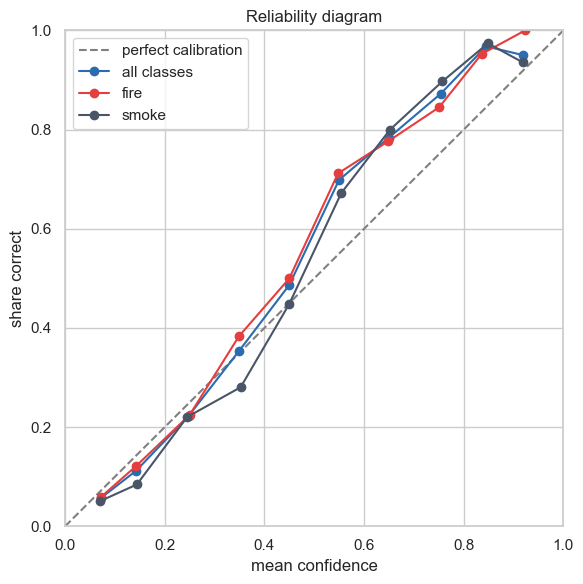

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/best_val_reliability_diagram.png


In [63]:
bin_edges = np.linspace(0, 1, CALIBRATION_BINS + 1)


def calibration_table(frame):
    binned = frame.copy()
    binned["bin"] = pd.cut(binned["confidence"], bins=bin_edges, include_lowest=True)
    table = binned.groupby("bin", observed=True).agg(
        predictions=("correct", "count"),
        mean_confidence=("confidence", "mean"),
        share_correct=("correct", "mean"),
    )
    return table


overall_calibration = calibration_table(calibration_results)
save_table(overall_calibration.round(3), "best_val_calibration_bins")

ece_rows = []
class_calibration = {}
for class_name in ["all classes"] + CLASS_ORDER:
    if class_name == "all classes":
        subset = calibration_results
    else:
        subset = calibration_results[calibration_results["class"] == class_name]
    if subset.empty:
        continue
    table = calibration_table(subset)
    class_calibration[class_name] = table
    weights = table["predictions"] / table["predictions"].sum()
    gaps = (table["share_correct"] - table["mean_confidence"]).abs()
    ece_rows.append({"class": class_name, "predictions": len(subset), "ECE": float((weights * gaps).sum())})
save_table(pd.DataFrame(ece_rows).set_index("class").round(3), "best_val_calibration_error")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect calibration")
calibration_colors = {"all classes": "#2b6cb0", "fire": "#e53e3e", "smoke": "#4a5568"}
for class_name, table in class_calibration.items():
    ax.plot(table["mean_confidence"], table["share_correct"], marker="o", label=class_name,
            color=calibration_colors[class_name])
ax.set_xlabel("mean confidence")
ax.set_ylabel("share correct")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Reliability diagram")
ax.legend()
plt.tight_layout()
save_figure(fig, "best_val_reliability_diagram")

#### Frame-level alarms

The live service does not count boxes. It asks one question per frame: is there at least one fire box (and one smoke box) above the threshold? This table answers that question on val, with the per-class thresholds:

| Column | Meaning |
|--------|---------|
| frames with the class | val images that have at least one label of the class |
| frame recall | share of those images where the model raised the alarm for that class |
| frames without the class | val images with no label of the class |
| false alarm rate | share of those images where the model still raised the alarm |
| false alarm rate on background | the same, only on images with no fire and no smoke at all |

The false alarm rate on background is the closest estimate of how often an empty SAMS camera would show a fire or smoke score above zero.

,threshold,frames with the class,frame recall,frames without the class,false alarm rate,background frames,false alarm rate on background
class,,,,,,,
fire,0.050,543,0.989,995,0.078,589,0.053
smoke,0.374,866,0.872,672,0.055,589,0.015


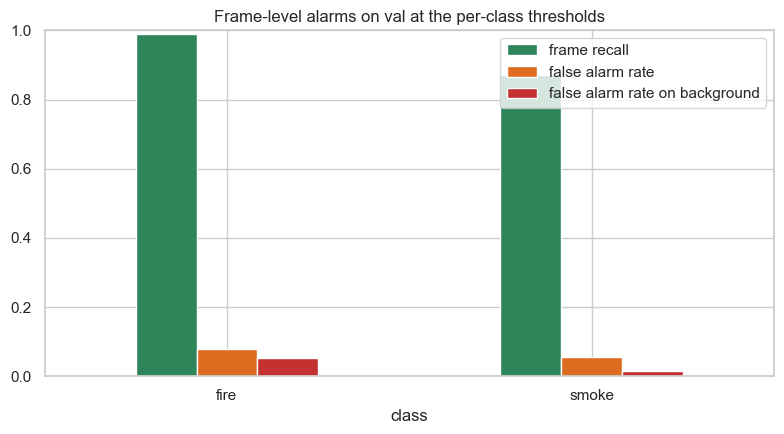

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/best_val_frame_level.png


In [64]:
frame_rows = []
for class_name in CLASS_ORDER:
    class_id = NAME_TO_ID[class_name]
    with_class = 0
    caught = 0
    without_class = 0
    false_alarms = 0
    background_frames = 0
    background_alarms = 0
    for image_path in VAL_IMAGES:
        key = str(image_path)
        has_label = False
        for label in VAL_LABELS[key]:
            if label[0] == class_id:
                has_label = True
        has_alarm = False
        for prediction in KEPT_PREDICTIONS[key]:
            if prediction[0] == class_id:
                has_alarm = True
        if has_label:
            with_class += 1
            if has_alarm:
                caught += 1
        else:
            without_class += 1
            if has_alarm:
                false_alarms += 1
        if not VAL_LABELS[key]:
            background_frames += 1
            if has_alarm:
                background_alarms += 1
    frame_rows.append({
        "class": class_name,
        "threshold": CLASS_CONF.get(class_name, GLOBAL_CONF),
        "frames with the class": with_class,
        "frame recall": caught / max(with_class, 1),
        "frames without the class": without_class,
        "false alarm rate": false_alarms / max(without_class, 1),
        "background frames": background_frames,
        "false alarm rate on background": background_alarms / max(background_frames, 1),
    })
FRAME_LEVEL = pd.DataFrame(frame_rows).set_index("class")
save_table(FRAME_LEVEL.round(3), "best_val_frame_level")

fig, ax = plt.subplots(figsize=(8, 4.5))
FRAME_LEVEL[["frame recall", "false alarm rate", "false alarm rate on background"]].plot(
    kind="bar", ax=ax, color=["#2f855a", "#dd6b20", "#c53030"])
ax.set_ylim(0, 1)
ax.set_title("Frame-level alarms on val at the per-class thresholds")
plt.xticks(rotation=0)
plt.tight_layout()
save_figure(fig, "best_val_frame_level")

#### Where the model misses fire and smoke

The six val images with the most missed labels. Green boxes are the labels, red dashed boxes are the predictions kept at the per-class thresholds, with their confidence. Look for a pattern: tiny distant fires, thin smoke, night scenes, or labels that are themselves wrong.

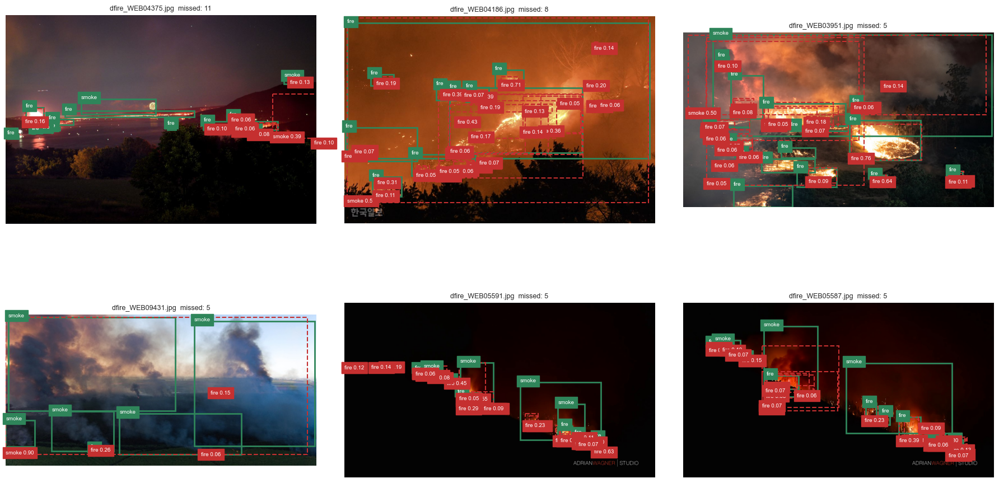

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/best_val_missed_labels.png


In [65]:
def draw_predictions(ax, image_path, predictions):
    """Draw [class_id, confidence, xc, yc, w, h] predictions as dashed red boxes."""
    with Image.open(image_path) as image:
        width, height = image.size
    for prediction in predictions:
        left = (prediction[2] - prediction[4] / 2) * width
        top = (prediction[3] - prediction[5] / 2) * height
        ax.add_patch(patches.Rectangle((left, top), prediction[4] * width, prediction[5] * height,
                                       fill=False, linewidth=1.5, edgecolor="#c53030", linestyle="--"))
        ax.text(left, top + prediction[5] * height, f"{CLASS_NAMES[prediction[0]]} {prediction[1]:.2f}",
                color="white", fontsize=7, backgroundcolor="#c53030")


missed_per_image = false_negative.sum(axis=1)
worst_order = np.argsort(-missed_per_image)
miss_gallery = []
for image_number in worst_order[:6]:
    if missed_per_image[image_number] > 0:
        miss_gallery.append(image_number)

if not miss_gallery:
    display(pd.DataFrame([{"result": "No labels were missed on val"}]))
else:
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    for ax in axes.flatten():
        ax.axis("off")
    for ax, image_number in zip(axes.flatten(), miss_gallery):
        image_path = VAL_IMAGES[image_number]
        draw_boxes(ax, image_path, VAL_LABELS[str(image_path)], color="#2f855a")
        draw_predictions(ax, image_path, KEPT_PREDICTIONS[str(image_path)])
        ax.set_title(f"{image_path.name[:35]}  missed: {int(missed_per_image[image_number])}", fontsize=9)
    plt.tight_layout()
    save_figure(fig, "best_val_missed_labels")

#### Worst false alarms on background images

The six val background images (no fire, no smoke labelled) with the most confident kept prediction. Each of these would have raised a fire or smoke score in the live service. If they are mostly sunsets or lamps, more such images in `EXTRA_BACKGROUND_DIR` is the fix. If some of them actually show fire or smoke, the label is wrong, not the model.

In [ ]:
def strongest_of(row):
    return row["strongest confidence"]


false_alarm_rows = []
for image_path in VAL_IMAGES:
    key = str(image_path)
    if VAL_LABELS[key] or not KEPT_PREDICTIONS[key]:
        continue
    strongest = 0.0
    for prediction in KEPT_PREDICTIONS[key]:
        strongest = max(strongest, prediction[1])
    false_alarm_rows.append({"image": image_path, "strongest confidence": strongest})
false_alarm_rows = sorted(false_alarm_rows, key=strongest_of, reverse=True)

if not false_alarm_rows:
    display(pd.DataFrame([{"result": "No false alarms on val background images"}]))
else:
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    for ax in axes.flatten():
        ax.axis("off")
    for ax, row in zip(axes.flatten(), false_alarm_rows[:6]):
        image_path = row["image"]
        draw_boxes(ax, image_path, [])
        draw_predictions(ax, image_path, KEPT_PREDICTIONS[str(image_path)])
        ax.set_title(f"{image_path.name[:35]}  strongest: {row['strongest confidence']:.2f}", fontsize=9)
    plt.tight_layout()
    save_figure(fig, "best_val_false_alarms")

### 12.6 Robustness to bad camera conditions

`ROBUST_SAMPLE` val images are scored as they are, and again after one fixed degradation at a time. Only the image changes, so the labels are the same. A large drop shows which condition to add more training data for.

| Condition | What it imitates |
|-----------|------------------|
| motion blur | Camera shake or a pan-tilt camera moving |
| dark | Night or a badly lit hall |
| heavy jpeg | A heavily compressed stream |
| low resolution | A distant fire on a low-resolution camera |
| sensor noise | A cheap or overheating camera sensor at night |

Each degradation is wrapped in its own seeded `A.Compose`, so the same images get the same degradation on every rerun.

In [67]:
robust_rng = np.random.default_rng(SEED)
sample_count = min(ROBUST_SAMPLE, len(VAL_IMAGES))
chosen_positions = sorted(robust_rng.choice(len(VAL_IMAGES), size=sample_count, replace=False))
robust_images = []
for position in chosen_positions:
    robust_images.append(VAL_IMAGES[int(position)])

CONDITIONS = {
    "clean": None,
    "motion blur": A.Compose([A.MotionBlur(blur_limit=(9, 13), p=1.0)], seed=SEED),
    "dark": A.Compose([A.RandomBrightnessContrast(brightness_limit=(-0.45, -0.35), contrast_limit=(0.0, 0.0), p=1.0)], seed=SEED),
    "heavy jpeg": A.Compose([A.ImageCompression(quality_range=(10, 20), p=1.0)], seed=SEED),
    "low resolution": A.Compose([A.Downscale(scale_range=(0.3, 0.35), p=1.0)], seed=SEED),
    "sensor noise": A.Compose([A.GaussNoise(std_range=(0.08, 0.12), p=1.0)], seed=SEED),
}

robust_rows = []
for condition, transform in CONDITIONS.items():
    folder = "robust_" + condition.replace(" ", "_")
    image_dir = MERGED / "images" / folder
    label_dir = MERGED / "labels" / folder
    for directory in [image_dir, label_dir]:
        if directory.exists():
            shutil.rmtree(directory)
        directory.mkdir(parents=True)

    written = []
    for image_path in robust_images:
        target = image_dir / image_path.name
        if transform is None:
            shutil.copy2(image_path, target)
        else:
            pixels = np.array(Image.open(image_path).convert("RGB"))
            changed = transform(image=pixels)["image"]
            Image.fromarray(changed).save(target, quality=95)
        shutil.copy2(label_path_for(image_path), label_dir / f"{image_path.stem}.txt")
        written.append(target)

    list_path = write_list(folder, written)
    # Evaluation only: the train entry is required by the YAML format but never read here
    data_yaml = write_data_yaml(folder, list_path, list_path, list_path)
    metrics = score_model(BEST_WEIGHTS, data_yaml, BEST_IMGSZ_FINAL)
    per_class = per_class_frame(metrics)
    row = {
        "condition": condition,
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
    }
    for class_name in CLASS_ORDER:
        row[f"{class_name} recall"] = class_value(per_class, class_name, "recall")
    robust_rows.append(row)

robust_table = pd.DataFrame(robust_rows).set_index("condition")
clean_score = robust_table.loc["clean", "mAP50-95"]
robust_table["mAP50-95 drop vs clean"] = clean_score - robust_table["mAP50-95"]
save_table(robust_table.round(3), "best_val_robustness")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1607.0±543.1 MB/s, size: 77.0 KB)
val: Scanning /content/SAMS/datasets/vision/hazard/merged/labels/robust_clean... 600 images, 219 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 600/600 1.5Kit/s 0.4s
val: New cache created: /content/SAMS/datasets/vision/hazard/merged/labels/robust_clean.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 5.6it/s 6.7s
                   all        600        990      0.732      0.653      0.703        0.4
Speed: 0.9ms preprocess, 6.0ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (pin

,precision,recall,mAP50,mAP50-95,fire recall,smoke recall,mAP50-95 drop vs clean
condition,,,,,,,
clean,0.732,0.653,0.703,0.400,0.561,0.745,0.000
motion blur,0.712,0.604,0.659,0.362,0.498,0.709,0.037
dark,0.660,0.522,0.573,0.296,0.438,0.607,0.104
heavy jpeg,0.631,0.527,0.565,0.288,0.483,0.570,0.112
low resolution,0.721,0.544,0.623,0.334,0.433,0.655,0.066
sensor noise,0.530,0.382,0.404,0.181,0.481,0.284,0.219


The chart shows mAP50-95 and the recall of each class under every condition. The clean bar is the reference. Watch the fire recall bar most: a condition that halves it is a condition where a real fire would go unnoticed.

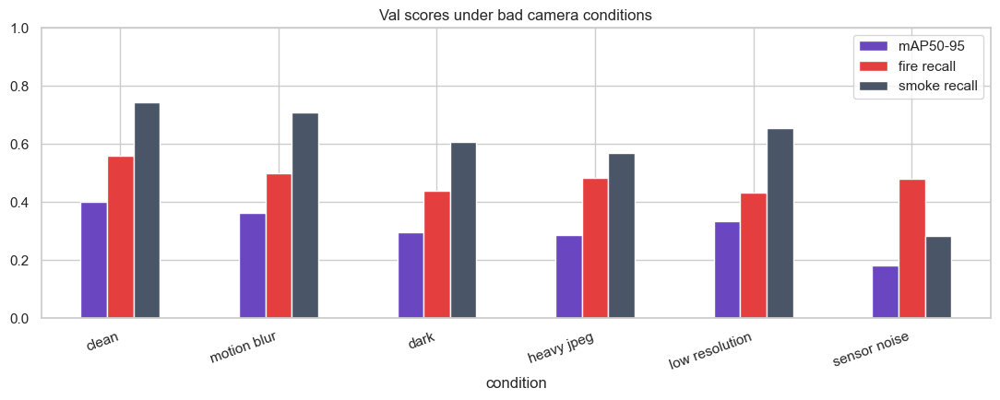

Saved figure: /content/drive/MyDrive/SAMS/results/vision/hazard/best_val_robustness.png


In [68]:
fig, ax = plt.subplots(figsize=(11, 4.5))
robust_table[["mAP50-95", "fire recall", "smoke recall"]].plot(kind="bar", ax=ax, color=["#6b46c1", "#e53e3e", "#4a5568"])
ax.set_ylim(0, 1)
ax.set_title("Val scores under bad camera conditions")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
save_figure(fig, "best_val_robustness")

## 13. Final test, live metadata, export check, model card

### 13.1 Score the chosen model once on test

The chosen weights are copied to `models/vision/hazard/best.pt` and scored on the test split. This is the only time test is used to measure the model.

In [69]:
PROMOTED = MODELS_DIR / "best.pt"
shutil.copy2(BEST_WEIGHTS, PROMOTED)

final_test_yaml = write_data_yaml("final_test", TRAIN_LISTS[WINNER["recipe"]["data_name"]], VAL_LIST, TEST_LIST)
test_metrics = score_model(PROMOTED, final_test_yaml, BEST_IMGSZ_FINAL, split="test", plots=True, name="hazard_final_test")
test_per_class = per_class_frame(test_metrics).reindex(CLASS_ORDER)

TEST_RESULT = {
    "images": len(TEST_IMAGES),
    "precision": float(test_metrics.box.mp),
    "recall": float(test_metrics.box.mr),
    "map50": float(test_metrics.box.map50),
    "map50_95": float(test_metrics.box.map),
}
for class_name in CLASS_ORDER:
    TEST_RESULT[f"{class_name}_recall"] = class_value(test_per_class, class_name, "recall")
    TEST_RESULT[f"{class_name}_map50_95"] = class_value(test_per_class, class_name, "mAP50-95")

comparison_rows = []
for metric_name in ["precision", "recall", "map50", "map50_95", "fire_recall", "smoke_recall"]:
    comparison_rows.append({
        "metric": metric_name,
        "val": WINNER["summary"][metric_name],
        "test": TEST_RESULT[metric_name],
        "test minus val": TEST_RESULT[metric_name] - WINNER["summary"][metric_name],
    })
save_table(pd.DataFrame(comparison_rows).set_index("metric").round(4), "final_test_vs_val")
save_table(test_per_class.round(3), "final_test_per_class")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2926.5±1193.8 MB/s, size: 171.8 KB)
val: Scanning /content/SAMS/datasets/vision/hazard/merged/labels/test... 3941 images, 1813 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3941/3941 1.7Kit/s 2.3s
val: /content/SAMS/datasets/vision/hazard/merged/images/test/dfire_WEB11243.jpg: corrupt JPEG restored and saved
val: /content/SAMS/datasets/vision/hazard/merged/images/test/dfire_WEB11244.jpg: corrupt JPEG restored and saved
val: /content/SAMS/datasets/vision/hazard/merged/images/test/dfire_WEB11245.jpg: corrupt JPEG restored and saved
val: /content/SAMS/datasets/vision/hazard/merged/images/test/dfire_WEB11313.jpg: corrupt JPEG restored and saved
val: /content/SAMS/datasets/vision/hazard/merged/images/test/dfire_WEB11315.jpg: corrupt JPEG restored and saved
val: /content/SAMS/datase

,val,test,test minus val
metric,,,
precision,0.7302,0.7290,-0.0011
recall,0.6763,0.6600,-0.0163
map50,0.7214,0.7179,-0.0035
map50_95,0.4130,0.3937,-0.0193
fire_recall,0.6072,0.6285,0.0213
smoke_recall,0.7455,0.6916,-0.0539


,precision,recall,mAP50,mAP50-95
class,,,,
fire,0.696,0.628,0.691,0.349
smoke,0.762,0.692,0.745,0.438


### 13.2 Metadata for the live service

`hazard_inference.py` checks that `classes`, `conf`, `imgsz`, `model_id`, and `score_window` are all present (`load_spec`), then maps each model output name to `fire` or `smoke` through `classes` (`_kind`) and passes `conf` and `imgsz` to `predict` (`detect_hazards`). `smooth_scores` reads `score_window`.

The other keys are extra and are ignored by the current service: `class_conf` holds the per-class thresholds from 12.4, `class_names` the raw output names, and the rest records where the model came from and how well it scored.

In [70]:
promoted_model = YOLO(str(PROMOTED))
promoted_names = {}
for class_id, class_name in promoted_model.names.items():
    promoted_names[int(class_id)] = str(class_name)
del promoted_model

winner_train_list = TRAIN_LISTS[WINNER["recipe"]["data_name"]]
dataset_hash = hashlib.sha256(Path(winner_train_list).read_bytes()).hexdigest()

frame_level_record = {}
for class_name in CLASS_ORDER:
    frame_level_record[class_name] = {
        "frame_recall": float(FRAME_LEVEL.loc[class_name, "frame recall"]),
        "false_alarm_rate_on_background": float(FRAME_LEVEL.loc[class_name, "false alarm rate on background"]),
    }

metadata = {
    "model_id": f"{Path(WINNER['recipe']['weights']).stem}_dfire",
    "best_experiment_id": WINNER_ID,
    "trained_utc": datetime.now(timezone.utc).isoformat(),
    "classes": HAZARD_CLASSES,
    "conf": GLOBAL_CONF,
    "class_conf": CLASS_CONF,
    "imgsz": BEST_IMGSZ_FINAL,
    "score_window": SCORE_WINDOW,
    "class_names": promoted_names,
    "dataset": DATASET_NAME,
    "dataset_url": DATASET_URL,
    "dataset_details": {
        "hf_mirror": DATASET_HF_REPO,
        "license": DATASET_LICENSE,
        "train_set": WINNER["recipe"]["data_name"],
        "train_images": len(read_list(winner_train_list)),
        "val_images": len(VAL_IMAGES),
        "test_images": len(TEST_IMAGES),
        "train_list_sha256": dataset_hash,
        "near_duplicate_bits": NEAR_DUP_BITS,
        "images_removed_as_duplicates": len(DROPPED),
    },
    "recipe": {
        "weights_in": WINNER["recipe"]["weights"],
        "two_stage": WINNER["recipe"]["two_stage"],
        "freeze_layers_stage_a": FREEZE_LAYERS,
        "patience": PATIENCE,
        "hyperparameters": WINNER["recipe"]["hparams"],
    },
    "val": {
        "map50": WINNER["summary"]["map50"],
        "map50_95": WINNER["summary"]["map50_95"],
        "fire_recall": WINNER["summary"]["fire_recall"],
        "smoke_recall": WINNER["summary"]["smoke_recall"],
        "frame_level": frame_level_record,
    },
    "test": TEST_RESULT,
    "versions": {
        "ultralytics": ultralytics.__version__,
        "torch": torch.__version__,
        "albumentations": A.__version__,
    },
}
METADATA_PATH = MODELS_DIR / "metadata.json"
with METADATA_PATH.open("w") as handle:
    json.dump(metadata, handle, indent=2, default=str)

metadata_view = pd.DataFrame([
    {"field": "model_id", "value": metadata["model_id"]},
    {"field": "best_experiment_id", "value": WINNER_ID},
    {"field": "classes", "value": json.dumps(HAZARD_CLASSES)},
    {"field": "conf", "value": GLOBAL_CONF},
    {"field": "class_conf", "value": json.dumps(CLASS_CONF)},
    {"field": "imgsz", "value": BEST_IMGSZ_FINAL},
    {"field": "score_window", "value": SCORE_WINDOW},
    {"field": "val mAP50-95", "value": round(WINNER["summary"]["map50_95"], 4)},
    {"field": "test mAP50-95", "value": round(TEST_RESULT["map50_95"], 4)},
    {"field": "weights", "value": str(PROMOTED)},
]).set_index("field")
save_table(metadata_view, "live_metadata_summary")

,value
field,
model_id,yolov8s_dfire
best_experiment_id,hazard_e5_yolov8s
classes,"{""fire"": [""fire""], ""smoke"": [""smoke""]}"
conf,0.05
class_conf,"{""fire"": 0.05, ""smoke"": 0.374}"
imgsz,960
score_window,1
val mAP50-95,0.413
test mAP50-95,0.3937


### 13.3 Read the metadata back the way the live service does

This cell repeats the checks in `load_spec` and `_kind` on the saved file and the promoted weights. If a model output name would not map to `fire` or `smoke`, the live service would silently ignore those boxes, so the notebook stops here instead.

In [71]:
def service_norm(label):
    text = str(label).strip().lower().replace("_", " ").replace("-", " ")
    return " ".join(text.split())


saved_spec = json.loads(METADATA_PATH.read_text())
missing_keys = []
for key in ["classes", "conf", "imgsz", "model_id", "score_window"]:
    if key not in saved_spec:
        missing_keys.append(key)
if missing_keys:
    raise RuntimeError(f"metadata.json is missing {missing_keys}")

mapping_rows = []
kinds_found = set()
for class_id, class_name in promoted_names.items():
    live_kind = None
    for kind, names in saved_spec["classes"].items():
        normalised = set()
        for name in names:
            normalised.add(service_norm(name))
        if service_norm(class_name) in normalised:
            live_kind = kind
    if live_kind is not None:
        kinds_found.add(live_kind)
    mapping_rows.append({"model output id": class_id, "model output name": class_name, "live service kind": live_kind})
save_table(pd.DataFrame(mapping_rows).set_index("model output id"), "live_class_mapping")

for kind in ["fire", "smoke"]:
    if kind not in kinds_found:
        raise RuntimeError(f"No model output maps to {kind}. The live service would never report {kind}_score.")
print("metadata.json passes the live service checks.")

,model output name,live service kind
model output id,,
0,smoke,smoke
1,fire,fire


metadata.json passes the live service checks.


### 13.4 Export check

The model is exported to ONNX, the format most deployment runtimes accept. Both PyTorch and ONNX are scored on val (this does not change any model choice) and timed on `FPS_IMAGES` val images, one image at a time, the way the live stream runs. Without `onnxruntime-gpu`, the ONNX model runs on the CPU, so its speed shows CPU deployment.

In [72]:
def measure_fps(weights_path, images, imgsz):
    model = YOLO(str(weights_path))
    for image_path in images[:5]:
        model.predict(str(image_path), imgsz=imgsz, device=YOLO_DEVICE, verbose=False)
    started = time.time()
    for image_path in images:
        model.predict(str(image_path), imgsz=imgsz, device=YOLO_DEVICE, verbose=False)
    elapsed = time.time() - started
    del model
    free_memory()
    return len(images) / elapsed


export_model = YOLO(str(PROMOTED))
onnx_path = Path(export_model.export(format="onnx", imgsz=BEST_IMGSZ_FINAL, simplify=True))
del export_model

timing_images = VAL_IMAGES[:FPS_IMAGES]
export_rows = []
for format_name, weights_path in [("PyTorch", PROMOTED), ("ONNX", onnx_path)]:
    metrics = score_model(weights_path, BEST_DATA_YAML, BEST_IMGSZ_FINAL, split="val")
    export_rows.append({
        "format": format_name,
        "file": weights_path.name,
        "size MB": round(weights_path.stat().st_size / 1e6, 1),
        "val mAP50": float(metrics.box.map50),
        "val mAP50-95": float(metrics.box.map),
        "frames per second": measure_fps(weights_path, timing_images, BEST_IMGSZ_FINAL),
    })
save_table(pd.DataFrame(export_rows).set_index("format").round(3), "export_check")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 64.0 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/SAMS/models/vision/hazard/best.pt' with input shape (1, 3, 960, 960) BCHW and output shape(s) (1, 6, 18900) (21.5 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 10 packages in 420ms
Prepared 2 packages in 260ms
Installed 2 packages in 7ms
 + colorama==0.4.6
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 3.4s, saved as '/con

,file,size MB,val mAP50,val mAP50-95,frames per second
format,,,,,
PyTorch,best.pt,22.5,0.721,0.413,59.081
ONNX,best.onnx,45.0,0.721,0.407,4.869


## 14. Limitations and next steps

**Known limitations**

1. **One public source.** D-Fire is web images and video frames. Val and test come from the same collection as training, so they say little about a new SAMS site. There is only one source, so no leave-one-source-out check was possible.
2. **Near-duplicate threshold is a heuristic.** A difference hash with `NEAR_DUP_BITS` catches repeated and nearly identical frames, but not the same scene filmed from a slightly different angle. Some scene overlap between train and test may remain.
3. **Smoke boxes are fuzzy.** Annotators draw smoke edges differently, so mAP50-95 for smoke understates how useful the detector is at frame level. The frame-level table in 12.5 is the better guide for SAMS.
4. **Few industrial scenes.** D-Fire is mostly outdoor and wildland fire. Electrical, chemical, and machine fires inside a factory are under-represented.
5. **One threshold in the live service.** `metadata.json` holds per-class thresholds in `class_conf`, but `hazard_inference.py` only reads `conf`, so smoke runs at the lower fire threshold.
6. **No temporal smoothing chosen from data.** `score_window` is 1. Still images cannot show how many frames to average, so this needs SAMS video.

**Next steps, in order of value**

1. Label 200 to 500 frames from the SAMS cameras (with and without fire or smoke) and add them as a separate test set, then as training data.
2. Put empty frames from the SAMS cameras into `EXTRA_BACKGROUND_DIR`, especially welding, warning lights, steam, and dust, which are the likely false alarms on site.
3. Update `hazard_inference.py` to apply `class_conf` per class (predict at the lowest threshold, then drop boxes below their own class threshold).
4. Choose `score_window` from recorded SAMS video, trading alarm delay against flicker.
5. Add an indoor industrial fire dataset as a second source, which would also make a leave-one-source-out check possible.